# Livrable final - Tournées de livraison (CVRP) : modélisation, résolution exacte et métaheuristique

*Groupe N°5 :* Jean Dona, Ann-Dany, Protais, Axel, Yannick  -  *Tuteur :* Ahmed NAIT CHABANE

**Fil de ce notebook.** On part du modèle PLNE du livrable 1 (corrigé), on le résout **exactement** avec PuLP/CBC pour savoir jusqu'où l'exact peut aller, puis on construit une **métaheuristique** (recuit simulé renforcé) capable de traiter des milliers de clients. On évalue ensuite son comportement avec un **plan d'expérience** (≥ 20 instances du benchmark VRPLIB avec solutions de référence), et on termine par l'**extension CVRPTW** (fenêtres de temps).

**Mode d'emploi.** Le dossier contient `data/X/` (100 instances VRPLIB), `data/bks_X.json` (meilleures solutions connues) et `cache/` (résultats déjà calculés). Par défaut, les cellules d'expérience **rechargent** `cache/` (exécution en quelques secondes). Pour tout recalculer (≈ 20 min) : lancer Jupyter avec la variable d'environnement `RECALCULER=1`. Tous les tirages aléatoires sont graînés : les résultats sont reproductibles.

## Plan
1. Rappel du problème et corrections apportées au livrable 1
2. Données : représentation, générateur d'instances, lecture VRPLIB, vérificateur
3. Résolution exacte : PLNE avec PuLP / CBC
4. Implémentation des métaheuristiques et premier essai
6. Choix de la méthode heuristique
5. Recuit simulé renforcé : formalisation
7. Comportement de l'algorithme : trajectoire
8. Validation face à l'exact (petites instances)
9. Plan d'expérience et étude statistique
10. Extension CVRPTW
11. Limites, améliorations, conclusion
12. Références

## 1. Rappel du problème et modèle PLNE

**Problème (CVRP).** Un dépôt $0$, $n$ clients $C=\{1,\dots,n\}$ de demande $q_i\ge 1$, au plus $k$ camions identiques de capacité $Q$. On cherche des tournées (départ et retour au dépôt) qui servent chaque client une seule fois, sans dépasser $Q$, de **longueur totale minimale**. Les durées $t_{ij}$ sont les distances euclidiennes arrondies à l'entier (convention VRPLIB).

**Formalisation des données**
##### 1 Le réseau
On modélise le réseau par un **graphe orienté complet** $G = (V, A)$ :

- $V = \{0, 1, \dots, n\}$ : ensemble des sommets
  - $0$ : le **dépôt**
  - $C = \{1, \dots, n\}$ : les **clients** ($n$ clients)
- $A = \{(i, j) \mid i, j \in V,\ i \neq j\}$ : les arcs (trajet direct de $i$ vers $j$)

Chaque arc $(i,j) \in A$ est muni d'une **durée de trajet** $t_{ij} \ge 0$ (matrice $T = (t_{ij})$). Dans un réseau routier réel, $t_{ij}$ est la durée du plus court chemin entre $i$ et $j$ : on se ramène ainsi à un graphe complet.

##### 2 Les demandes et la flotte
- $q_i \in \mathbb{N}$ : **demande** du client $i \in C$ ; on pose $q_0 = 0$
- $K = \{1, \dots, k\}$ : ensemble des **camions** (identiques)
- $Q \in \mathbb{N}$ : **capacité** de chaque camion

**Modèle PLNE** (variables $x_{ij}\in\{0,1\}$, charges cumulées $u_i$) :
$$\min \sum_{(i,j)} t_{ij}x_{ij}\quad\text{s.c.}\quad
\sum_{j} x_{ij}=1,\ \ \sum_{i} x_{ij}=1\ (i,j\in C),\ \ \sum_{j\in C}x_{0j}\le k,$$
$$u_i-u_j+Q\,x_{ij}\le Q-q_j\ \ (i\neq j\in C),\qquad q_i\le u_i\le Q.$$

### Importation des bibliothèques et ressources nécéssaires

In [63]:
import os, json, time, math, random, re, statistics
from array import array
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
DOSSIER_X = "data/X"
BKS = json.load(open("data/bks_X.json"))["bks"]          # meilleures solutions connues (instances X)
CACHE = "cache"
os.makedirs(CACHE, exist_ok=True)
RECALCULER = os.environ.get("RECALCULER", "0") == "1"    # True : refait tous les calculs


def avec_cache(nom, calcul):
    # Exécute `calcul()` et sauvegarde le résultat ; sinon recharge le fichier cache/<nom>.json
    chemin = f"{CACHE}/{nom}.json"
    if not RECALCULER and os.path.exists(chemin):
        return json.load(open(chemin))
    res = calcul()
    json.dump(res, open(chemin, "w"))
    return res

## 2. Données : représentation, générateur d'instances, vérificateur

### 2.1 Représentation
Une instance est un dictionnaire : coordonnées `x, y`, demandes `q` (avec `q[0]=0` pour le dépôt), capacité `Q`, nombre maximal de camions `k` et matrice des distances `D`.
Une **solution** est une liste de tournées ; chaque tournée est la liste de ses clients (le dépôt est implicite au début et à la fin).

### 2.2 Lecture des instances de vrplib

In [30]:
def matrice_distances(x, y):
    """Matrice des distances EUC_2D arrondies. Stockée en lignes `array('d')` :
    accès D[i][j] rapide et mémoire 8 octets/valeur (n = 5000 -> 200 Mo)."""
    xs, ys = np.asarray(x, float), np.asarray(y, float)
    lignes = []
    for i in range(len(xs)):
        d = np.floor(np.hypot(xs - xs[i], ys - ys[i]) + 0.5)
        a = array("d")
        a.frombytes(d.astype(np.float64).tobytes())
        lignes.append(a)
    return lignes


def construire_instance(nom, x, y, q, Q, k=None, **extra):
    """Assemble le dictionnaire d'instance (x, y, q indexés de 0 à n ; q[0] = 0)."""
    n = len(x) - 1
    inst = {"nom": nom, "n": n, "x": list(x), "y": list(y), "q": list(q), "Q": Q,
            "D": matrice_distances(x, y)}
    inst["kmin"] = math.ceil(sum(q) / Q)
    inst["k"] = k if k is not None else n          # k = nombre max de camions
    inst.update(extra)
    return inst


def _premier_ajustement_decroissant(q, Q):
    """Nombre de camions d'une répartition FFD (borne supérieure du nombre minimal)."""
    camions = []
    for d in sorted(q[1:], reverse=True):
        for i, c in enumerate(camions):
            if c + d <= Q:
                camions[i] += d
                break
        else:
            camions.append(d)
    return len(camions)


def generer_instance(n, seed=0, depot="C", clients="R", demande="1-10", r=8.0,
                     grille=1000, marge=None, remplissage=0.92):
    """Générateur d'instances CVRP inspiré de Uchoa et al. (2017).

    depot   : "C" centre, "E" coin (excentré), "R" aléatoire
    clients : "R" uniformes, "C" regroupés en grappes, "RC" moitié-moitié
    demande : "U" unitaire, "1-10", "1-100", "50-100", "SL" (beaucoup de petites, quelques grosses)
    r       : nombre moyen de clients par tournée ; remplissage : taux de remplissage visé des camions
              (la capacité vaut Q = r·demande_moyenne / remplissage)
    marge   : k = (borne FFD) + marge camions autorisés (défaut : 10 % de la borne FFD, au moins 1)
    """
    rng = random.Random(seed)
    # dépôt
    if depot == "C":
        dep = (grille // 2, grille // 2)
    elif depot == "E":
        dep = (0, 0)
    else:
        dep = (rng.randint(0, grille), rng.randint(0, grille))
    # clients
    def uniforme():
        return (rng.randint(0, grille), rng.randint(0, grille))

    pts = set()
    n_uni = n if clients == "R" else (0 if clients == "C" else n // 2)
    n_grappes = rng.randint(3, 8)
    centres = [uniforme() for _ in range(n_grappes)]
    while len(pts) < n:
        if len(pts) < n_uni:
            p = uniforme()
        else:
            cx, cy = rng.choice(centres)
            p = (min(max(int(rng.gauss(cx, grille * 0.05)), 0), grille),
                 min(max(int(rng.gauss(cy, grille * 0.05)), 0), grille))
        if p != dep:
            pts.add(p)
    pts = list(pts)
    rng.shuffle(pts)
    # demandes
    def dem():
        if demande == "U":
            return 1
        if demande == "1-10":
            return rng.randint(1, 10)
        if demande == "1-100":
            return rng.randint(1, 100)
        if demande == "50-100":
            return rng.randint(50, 100)
        return rng.randint(50, 100) if rng.random() < 0.2 else rng.randint(1, 10)   # "SL"

    q = [0] + [dem() for _ in range(n)]
    Q = max(max(q), math.ceil(r * sum(q) / n / remplissage))
    x = [dep[0]] + [p[0] for p in pts]
    y = [dep[1]] + [p[1] for p in pts]
    ffd = _premier_ajustement_decroissant(q, Q)
    k = ffd + (marge if marge is not None else max(1, math.ceil(0.1 * ffd)))
    nom = f"G-n{n}-{depot}{clients}-{demande}-r{r:g}-s{seed}"
    return construire_instance(nom, x, y, q, Q, k=k)


def lire_vrplib(chemin, k_illimite=True):
    """Lit un fichier .vrp (format CVRPLIB, EUC_2D). Le k du nom est le NOMBRE MINIMAL de
    camions : la flotte n'est pas bornée dans le benchmark, donc k = n par défaut."""
    texte = open(chemin).read()
    Q = int(re.search(r"CAPACITY\s*:\s*(\d+)", texte).group(1))
    nom = re.search(r"NAME\s*:\s*(\S+)", texte).group(1)
    coord = re.search(r"NODE_COORD_SECTION(.*?)DEMAND_SECTION", texte, re.S).group(1).split()
    dem = re.search(r"DEMAND_SECTION(.*?)DEPOT_SECTION", texte, re.S).group(1).split()
    x = [float(v) for v in coord[1::3]]
    y = [float(v) for v in coord[2::3]]
    q = [int(v) for v in dem[1::2]]
    m = re.search(r"-k(\d+)", nom)
    inst = construire_instance(nom, x, y, q, Q, k=None if k_illimite else int(m.group(1)))
    if m:
        inst["kmin_nom"] = int(m.group(1))
    return inst

### 2.3 Vérificateur indépendant
Dans cette section, nous définissons les fonctions cout_tournee() et verifier() pour vérifier la validité des solutions plus tard.

In [31]:
def cout_tournee(D, r):
    if not r:
        return 0.0
    c = D[0][r[0]] + D[r[-1]][0]
    for a, b in zip(r, r[1:]):
        c += D[a][b]
    return c


def verifier(inst, routes):
    """Retourne (coût, faisable, message). Contrôle partition, capacité, nombre de camions."""
    n, Q, q, D = inst["n"], inst["Q"], inst["q"], inst["D"]
    routes = [r for r in routes if r]
    if sorted(c for r in routes for c in r) != list(range(1, n + 1)):
        return None, False, "clients manquants ou dupliqués"
    if len(routes) > inst["k"]:
        return None, False, f"{len(routes)} tournées > k = {inst['k']}"
    for r in routes:
        if sum(q[c] for c in r) > Q:
            return None, False, "capacité dépassée"
    return sum(cout_tournee(D, r) for r in routes), True, "ok"

## 3. Résolution exacte : PLNE avec PuLP / CBC

On implémente le modèle PLNE avec **PuLP**, résolu par **CBC** : le solveur résout d'abord la *relaxation linéaire* (variables $x\in[0,1]$) par l'algorithme du **simplexe**, puis **explore** un arbre de branchement (*branch-and-bound*) en coupant avec les bornes données par ces relaxations. L'option `relaxation=True` renvoie la valeur de la relaxation : une **borne inférieure** du coût optimal.

In [32]:
def resoudre_exact(inst, limite_temps=60, relaxation=False, msg=False):
    """PLNE du livrable 1 (contraintes (1)-(6)) résolu par CBC (simplexe + branch-and-bound).

    relaxation=True : variables x continues dans [0,1] -> borne inférieure (relaxation linéaire).
    Retourne dict(statut, cout, routes, temps)."""
    import time
    import pulp

    n, Q, q, D, k = inst["n"], inst["Q"], inst["q"], inst["D"], min(inst["k"], inst["n"])
    V, C = range(n + 1), range(1, n + 1)
    prob = pulp.LpProblem("CVRP", pulp.LpMinimize)
    cat = pulp.LpContinuous if relaxation else pulp.LpBinary
    x = {(i, j): pulp.LpVariable(f"x_{i}_{j}", lowBound=0, upBound=1, cat=cat) for i in V for j in V if i != j}
    u = {i: pulp.LpVariable(f"u_{i}", lowBound=q[i], upBound=Q) for i in C}                     # (5)
    prob += pulp.lpSum(D[i][j] * x[i, j] for (i, j) in x)                      # (0)
    for i in C:
        prob += pulp.lpSum(x[i, j] for j in V if j != i) == 1                  # (1)
        prob += pulp.lpSum(x[j, i] for j in V if j != i) == 1                  # (2)
    prob += pulp.lpSum(x[0, j] for j in C) <= k                                # (3)
    for i in C:
        for j in C:
            if i != j:
                prob += u[i] - u[j] + Q * x[i, j] <= Q - q[j]                  # (4)
    t0 = time.time()
    prob.solve(pulp.PULP_CBC_CMD(msg=msg, timeLimit=limite_temps))
    temps = time.time() - t0
    statut = pulp.LpStatus[prob.status]
    # sol_status : 1 = optimum prouvé, 2 = solution entière trouvée mais optimalité non prouvée
    res = {"statut": statut, "temps": temps, "cout": None, "routes": None,
           "optimal": prob.sol_status == pulp.LpSolutionOptimal}
    if prob.sol_status in (pulp.LpSolutionOptimal, pulp.LpSolutionIntegerFeasible):
        res["cout"] = pulp.value(prob.objective)
        if not relaxation:
            succ = {i: j for (i, j) in x if x[i, j].value() is not None and x[i, j].value() > 0.5}
            depart = [j for j in C if x[0, j].value() > 0.5]
            routes = []
            for j in depart:
                r, c = [], j
                while c != 0:
                    r.append(c)
                    c = succ[c]
                routes.append(r)
            res["routes"] = routes
    return res

In [9]:
def voisins(inst, nb=15):
    """nb plus proches clients de chaque client (dépôt exclu). Cache dans l'instance."""
    cle = ("_nn", nb)
    if cle in inst:
        return inst[cle]
    n, D = inst["n"], inst["D"]
    nb = min(nb, n - 1)
    nn = [[]]
    for i in range(1, n + 1):
        row = np.frombuffer(D[i], dtype=np.float64)[1:].copy()
        row[i - 1] = np.inf
        idx = np.argpartition(row, nb)[:nb]
        idx = idx[np.argsort(row[idx], kind="stable")]
        nn.append([int(j) + 1 for j in idx])
    inst[cle] = nn
    return nn


def savings(inst, nb=40):
    """Clarke & Wright parallèle. Les économies s_ij = d_0i + d_0j - d_ij ne sont calculées que
    pour les `nb` plus proches voisins (O(n·nb) au lieu de O(n²) : indispensable pour n > 1000)."""
    n, Q, q, D = inst["n"], inst["Q"], inst["q"], inst["D"]
    nn = voisins(inst, nb)
    paires = []
    for i in range(1, n + 1):
        Di, D0i = D[i], D[0][i]
        for j in nn[i]:
            if i < j or i not in nn[j]:                 # pas de doublon
                paires.append((D0i + D[0][j] - Di[j], i, j))
    paires.sort(reverse=True)
    route_de = list(range(n + 1))                       # numéro de tournée de chaque client
    tournees = {i: [i] for i in range(1, n + 1)}
    charge = {i: q[i] for i in range(1, n + 1)}
    for s, i, j in paires:
        if s <= 0:
            break
        a, b = route_de[i], route_de[j]
        if a == b or charge[a] + charge[b] > Q:
            continue
        ra, rb = tournees[a], tournees[b]
        # i et j doivent être aux extrémités de leur tournée
        if ra[-1] == i and rb[0] == j:
            nouvelle = ra + rb
        elif ra[0] == i and rb[-1] == j:
            nouvelle = rb + ra
        elif ra[-1] == i and rb[-1] == j:
            nouvelle = ra + rb[::-1]
        elif ra[0] == i and rb[0] == j:
            nouvelle = ra[::-1] + rb
        else:
            continue
        tournees[a] = nouvelle
        charge[a] += charge[b]
        for c in rb:
            route_de[c] = a
        del tournees[b], charge[b]
    res = list(tournees.values())
    # trop de tournées (flotte bornée) : on fusionne les plus petites (surcharge tolérée, pénalisée ensuite)
    while len(res) > inst["k"]:
        res.sort(key=lambda r: sum(q[c] for c in r))
        petite = res.pop(0)
        marges = [Q - sum(q[c] for c in r) for r in res]
        for c in sorted(petite, key=lambda c: -q[c]):          # chaque client va où il reste le plus de place
            m = max(range(len(res)), key=marges.__getitem__)
            res[m].append(c)
            marges[m] -= q[c]
    return res

,temps_exact_s,borne_lp_pct,savings_ecart_pct,optimal
n,,,,
5,0.11,74.31,0.00,True
6,0.18,79.50,0.00,True
7,0.56,63.18,2.53,True
8,0.77,73.14,0.00,True
9,1.63,72.05,0.00,True
10,2.37,68.07,1.21,True
11,7.21,61.57,0.02,True
12,8.89,67.15,4.12,True


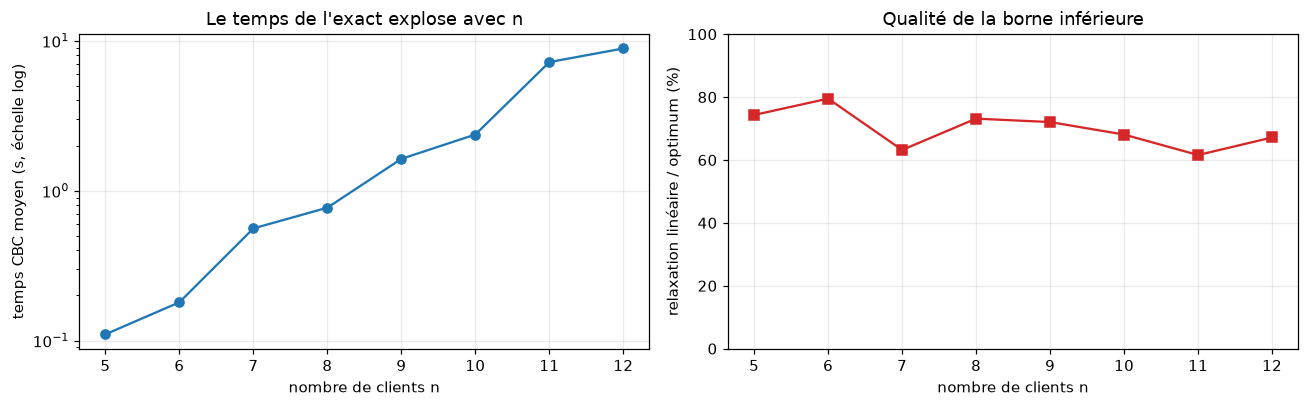

In [33]:
def exp_exact():
    # Instances de 5 à 12 clients, 3 par taille : exact (CBC, 120 s max), relaxation linéaire, savings
    lignes = []
    for n in range(5, 13):
        for sd in range(3):
            inst = generer_instance(n, seed=100 * n + sd, r=4)
            ex = resoudre_exact(inst, limite_temps=120)
            lp = resoudre_exact(inst, relaxation=True)
            lignes.append(dict(n=n, seed=sd, exact=ex["cout"], optimal=ex["optimal"], t_exact=ex["temps"],
                               lp=lp["cout"], savings=verifier(inst, savings(inst))[0],
                               verif=verifier(inst, ex["routes"])[1]))
    return lignes

df_ex = pd.DataFrame(avec_cache("exact", exp_exact))
df_ex["borne_lp_%"] = 100 * df_ex["lp"] / df_ex["exact"]
df_ex["savings_ecart_%"] = 100 * (df_ex["savings"] / df_ex["exact"] - 1)
resume = df_ex.groupby("n").agg(temps_exact_s=("t_exact", "mean"), borne_lp_pct=("borne_lp_%", "mean"),
                                 savings_ecart_pct=("savings_ecart_%", "mean"), optimal=("optimal", "all")).round(2)
display(resume)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].semilogy(resume.index, resume["temps_exact_s"].clip(lower=0.01), "o-")
ax[0].set_xlabel("nombre de clients n"); ax[0].set_ylabel("temps CBC moyen (s, échelle log)")
ax[0].set_title("Le temps de l'exact explose avec n")
ax[1].plot(resume.index, resume["borne_lp_pct"], "s-", color="tab:red")
ax[1].set_xlabel("nombre de clients n"); ax[1].set_ylabel("relaxation linéaire / optimum (%)")
ax[1].set_title("Qualité de la borne inférieure"); ax[1].set_ylim(0, 100)
plt.tight_layout(); plt.show()

**Interprétation.**
- **Temps** : de 0,1 s (5 clients) à ≈ 9 s (12 clients), soit un facteur ≈ 80 pour 7 clients de plus. L'axe est logarithmique et la courbe monte presque en ligne droite : la croissance est **exponentielle**. Lors de nos essais préliminaires, une instance de 15 clients n'était déjà plus résolue à l'optimum en 60 s.
- **Borne inférieure faible** : la relaxation linéaire vaut en moyenne ≈ 70 % de l'optimum (de 62 % à 80 % selon la taille). Cet écart de ≈ 30 % oblige CBC à explorer beaucoup de nœuds de branchement.
- **Clarke & Wright** (heuristique de construction rapide) est déjà à 0-4 % de l'optimum sur ces petites instances.
- **Conclusion** : l'exact valide le modèle et sert d'étalon sur de petites instances, mais il ne passe pas à l'échelle. Pour des centaines ou des milliers de clients, il faut une métaheuristique.

## 6. Implémentation et premier essai

### 6.1. Recherche tabou : principe

**Idée.** À chaque étape, on examine un grand nombre de mouvements possibles et on applique **le meilleur, même s'il dégrade la solution**. Le danger est de revenir en arrière au pas suivant et de tourner en rond. On garde donc une **mémoire** : ce qui vient d'être défait est interdit (tabou) pendant quelques itérations. La recherche est obligée d'aller ailleurs, ce qui la fait sortir des minima locaux.

**Contraste avec le recuit simulé.** Le recuit tire un mouvement au hasard et le juge. Le tabou examine un échantillon de mouvements et choisit le meilleur. Il est plus « réfléchi » à chaque pas, mais fait beaucoup moins de pas par seconde.

**Déroulement.**
1. Solution de départ : Clarke & Wright.
2. À chaque itération : tirer un échantillon d'une soixantaine de mouvements candidats (déplacer, échanger, 2-opt, 2-opt\*), puis garder le meilleur qui n'est pas tabou et l'appliquer.
3. Interdire pendant 8 à 20 itérations de recréer les arêtes que l'on vient de supprimer.
4. **Aspiration :** un mouvement tabou est quand même accepté s'il donne une nouvelle meilleure solution faisable.
5. Si la meilleure solution ne progresse plus depuis longtemps, on repart d'elle en vidant la mémoire (intensification).

**Réglages :** durée de l'interdiction, taille de l'échantillon, seuil de stagnation. La pénalité de capacité $\lambda$ est la même que pour le recuit.

In [34]:
# =============================================================================================
#  Recherche tabou et colonie de fourmis (MAX-MIN Ant System) pour le CVRP
#  Adaptés au noyau du notebook : inst = {"n","x","y","q","Q","D","k",...}, fonctions savings / voisins / verifier.
#  Chaque algorithme est exposé par une fonction  lancer_xxx(inst, limite_temps, seed) -> routes
#  (liste de tournées, chaque tournée = liste de clients sans le dépôt), qui s'arrête avant `limite_temps` secondes.
# =============================================================================================

# %% ------------------------------------------------------------------ RECHERCHE TABOU
def recherche_tabou(inst, limite_temps=10.0, seed=0, nb_voisins=15, taille_echantillon=60,
                    duree_tabou=(8, 20), init=None, stagnation=3000, p_vide=0.01):
    """Recherche tabou granulaire avec pénalité de capacité adaptative.

    À chaque itération on évalue `taille_echantillon` mouvements candidats (client c tiré au hasard, voisin v parmi
    ses `nb_voisins` plus proches ; relocate, swap, 2-opt*, 2-opt intra) et on applique le MEILLEUR mouvement
    admissible, même s'il dégrade la solution : c'est ce qui permet de sortir des minima locaux.
    Mémoire taboue : les arêtes retirées par un mouvement ne peuvent pas être recréées pendant `duree_tabou`
    itérations (tirage aléatoire dans l'intervalle). Aspiration : un mouvement tabou est accepté s'il donne une
    nouvelle meilleure solution faisable. Si le meilleur n'a pas progressé depuis `stagnation` itérations, on repart
    de la meilleure solution (intensification) avec une mémoire vidée.
    Retourne un dict : routes, cout, faisable, temps, iters.
    """
    rng = random.Random(seed)
    rnd = rng.random
    n, Q, q, D = inst["n"], inst["Q"], inst["q"], inst["D"]
    nn = voisins(inst, nb_voisins)
    N1 = n + 1
    t_debut = time.time()

    routes = [r[:] for r in (init if init is not None else savings(inst))]
    nb_non_vides = len(routes)
    R = min(inst["k"], max(nb_non_vides + 2, int(nb_non_vides * 1.15) + 2))
    R = max(R, nb_non_vides)
    routes += [[] for _ in range(R - len(routes))]
    pos, rid = [0] * N1, [0] * N1
    cum, load = [[] for _ in range(R)], [0] * R
    vides = set()

    def reindex(r):
        lst = routes[r]
        s = 0
        cu = []
        for p, c in enumerate(lst):
            rid[c] = r
            pos[c] = p
            s += q[c]
            cu.append(s)
        cum[r] = cu
        load[r] = s
        if lst:
            vides.discard(r)
        else:
            vides.add(r)

    for r in range(R):
        reindex(r)
    cout = sum(D[0][r[0]] + D[r[-1]][0] + sum(D[a][b] for a, b in zip(r, r[1:])) for r in routes if r)
    exc = sum(max(0, l - Q) for l in load)
    lam = max(1e-3, 2.0 * (sum(D[0][1:]) / n) / Q)
    lam_min, lam_max = lam / 10.0, max(lam * 30.0, cout / max(1, nb_non_vides))
    fenetre = max(200, n)
    meilleur_cout, meilleures = math.inf, None
    if exc == 0:
        meilleur_cout, meilleures = cout, [r[:] for r in routes if r]

    tabou = {}                                      # arête (clé entière) -> itération d'expiration
    t_min, t_max = duree_tabou
    it, derniere_amelio, faisables = 0, 0, 0

    def cle(a, b):
        return a * N1 + b if a < b else b * N1 + a

    while True:
        if (it & 7) == 0 and time.time() - t_debut >= limite_temps:
            break
        it += 1
        meilleur_val, mv = math.inf, None
        for _ in range(taille_echantillon):
            c = 1 + int(rnd() * n)
            nnc = nn[c]
            v = nnc[int(rnd() * len(nnc))]
            a, b, i, j = rid[c], rid[v], pos[c], pos[v]
            la, lb = routes[a], routes[b]
            pc = la[i - 1] if i else 0
            nc = la[i + 1] if i + 1 < len(la) else 0
            pv = lb[j - 1] if j else 0
            nv = lb[j + 1] if j + 1 < len(lb) else 0
            Dc, Dv, qc = D[c], D[v], q[c]
            lo = hi = 0
            m = rnd()
            if m < p_vide and vides and len(la) > 1:                         # 6 : tournée vide
                mt = 6
                dd = 2 * D[0][c] + D[pc][nc] - D[pc][c] - Dc[nc]
                al = load[a]
                de = (max(0, al - qc - Q) - max(0, al - Q)) + max(0, qc - Q)
                ajout = ((pc, nc),)
                retire = ((pc, c), (c, nc))
            else:
                m = rnd()
                if m < 0.40:                                                 # 0/1 relocate
                    mt = 0 if rnd() < 0.5 else 1
                    if mt == 0:
                        x, y = v, (nv if nv != c else nc)
                    else:
                        x, y = (pv if pv != c else pc), v
                    if a == b and x == pc and y == nc:
                        continue
                    dd = D[pc][nc] - D[pc][c] - Dc[nc] + D[x][c] + Dc[y] - D[x][y]
                    if a == b:
                        de = 0
                    else:
                        al, bl = load[a], load[b]
                        de = (max(0, al - qc - Q) - max(0, al - Q) + max(0, bl + qc - Q) - max(0, bl - Q))
                    ajout = ((pc, nc), (x, c), (c, y))
                    retire = ((pc, c), (c, nc), (x, y))
                elif m < 0.65:                                               # 2 swap
                    if a == b and (i - j == 1 or j - i == 1):
                        continue
                    mt = 2
                    dd = D[pc][v] + Dv[nc] + D[pv][c] + Dc[nv] - D[pc][c] - Dc[nc] - D[pv][v] - Dv[nv]
                    if a == b:
                        de = 0
                    else:
                        dq = q[v] - qc
                        al, bl = load[a], load[b]
                        de = (max(0, al + dq - Q) - max(0, al - Q) + max(0, bl - dq - Q) - max(0, bl - Q))
                    ajout = ((pc, v), (v, nc), (pv, c), (c, nv))
                    retire = ((pc, c), (c, nc), (pv, v), (v, nv))
                else:                                                        # 2-opt / 2-opt*
                    if a == b:
                        mt = 5
                        if i < j:
                            lo, hi, nlo, nhi = i, j, nc, nv
                        else:
                            lo, hi, nlo, nhi = j, i, nv, nc
                        if hi == lo + 1:
                            continue
                        xl, xh = la[lo], la[hi]
                        dd = D[xl][xh] + D[nlo][nhi] - D[xl][nlo] - D[xh][nhi]
                        de = 0
                        ajout = ((xl, xh), (nlo, nhi))
                        retire = ((xl, nlo), (xh, nhi))
                    else:
                        ha, hb = cum[a][i], cum[b][j]
                        ta, tb = load[a] - ha, load[b] - hb
                        al, bl = load[a], load[b]
                        if rnd() < 0.5:
                            mt = 3
                            dd = Dc[nv] + Dv[nc] - Dc[nc] - Dv[nv]
                            na_, nb_ = ha + tb, hb + ta
                            ajout = ((c, nv), (v, nc))
                        else:
                            mt = 4
                            dd = Dc[v] + D[nc][nv] - Dc[nc] - Dv[nv]
                            na_, nb_ = ha + hb, ta + tb
                            ajout = ((c, v), (nc, nv))
                        retire = ((c, nc), (v, nv))
                        de = (max(0, na_ - Q) + max(0, nb_ - Q) - max(0, al - Q) - max(0, bl - Q))
            val = dd + lam * de
            if val >= meilleur_val:
                continue
            # --- statut tabou : une arête (hors dépôt) à recréer est encore interdite ?
            est_tabou = False
            for (u, w) in ajout:
                if u and w and tabou.get(cle(u, w), 0) > it:
                    est_tabou = True
                    break
            if est_tabou and not (exc + de == 0 and cout + dd < meilleur_cout - 1e-9):
                continue
            meilleur_val = val
            mv = (mt, c, v, a, b, i, j, lo, hi, dd, de, retire)
        if mv is None:
            continue
        mt, c, v, a, b, i, j, lo, hi, dd, de, retire = mv
        la, lb = routes[a], routes[b]
        if mt <= 1:
            del la[i]
            idx = j + 1 if mt == 0 else j
            if a == b and i < idx:
                idx -= 1
            lb.insert(idx, c)
            reindex(a)
            if b != a:
                reindex(b)
        elif mt == 2:
            la[i], lb[j] = v, c
            reindex(a)
            if b != a:
                reindex(b)
        elif mt == 3:
            routes[a] = la[:i + 1] + lb[j + 1:]
            routes[b] = lb[:j + 1] + la[i + 1:]
            reindex(a)
            reindex(b)
        elif mt == 4:
            routes[a] = la[:i + 1] + lb[:j + 1][::-1]
            routes[b] = la[i + 1:][::-1] + lb[j + 1:]
            reindex(a)
            reindex(b)
        elif mt == 5:
            la[lo + 1:hi + 1] = la[lo + 1:hi + 1][::-1]
            reindex(a)
        else:
            e = next(iter(vides))
            del la[i]
            routes[e] = [c]
            reindex(a)
            reindex(e)
        cout += dd
        exc += de
        for (u, w) in retire:                       # les arêtes retirées deviennent tabou
            if u and w:
                tabou[cle(u, w)] = it + rng.randint(t_min, t_max)
        if exc == 0:
            faisables += 1
            if cout < meilleur_cout - 1e-9:
                meilleur_cout, meilleures = cout, [r[:] for r in routes if r]
                derniere_amelio = it
        if it % fenetre == 0:                       # adaptation de la pénalité
            if faisables < 0.1 * fenetre:
                lam = min(lam * 1.25, lam_max)
            elif faisables > 0.5 * fenetre:
                lam = max(lam / 1.25, lam_min)
            faisables = 0
            if len(tabou) > 50 * n:                 # nettoyage de la mémoire
                tabou = {k: e for k, e in tabou.items() if e > it}
        if meilleures is not None and it - derniere_amelio >= stagnation:     # intensification
            routes = [r[:] for r in meilleures] + [[] for _ in range(R - len(meilleures))]
            for r in range(R):
                reindex(r)
            cout = meilleur_cout
            exc = 0
            tabou.clear()
            derniere_amelio = it
    trouve = meilleures is not None
    if not trouve:
        meilleures, meilleur_cout = [r[:] for r in routes if r], cout
    return {"routes": meilleures, "cout": meilleur_cout, "faisable": trouve,
            "temps": time.time() - t_debut, "iters": it}

### 6.2. Recuit simulé : principe

**Idée.** On part d'une bonne solution et on la modifie par petites touches au hasard. Une modification qui améliore est toujours gardée. Une modification qui dégrade est parfois gardée, avec une probabilité qui diminue au fil du temps. Au début, la recherche accepte facilement de dégrader (elle explore). À la fin, elle n'accepte presque plus (elle affine). Accepter parfois une dégradation permet de sortir d'un minimum local.

**Le paramètre qui contrôle tout : la température $T$.** Une dégradation $\Delta f>0$ est acceptée avec la probabilité $e^{-\Delta f/T}$. Si $T$ est grand, cette probabilité est proche de 1. Si $T$ est petit, elle est proche de 0. On fait donc baisser $T$ progressivement (refroidissement).

**Déroulement.**
1. Construire une solution de départ (Clarke & Wright).
2. Répéter : choisir un client et un voisin proche, tirer un petit mouvement (déplacer, échanger, inverser un morceau), calculer son effet sur le coût $\Delta f$, puis l'accepter ou non selon la règle ci-dessus.
3. Faire baisser $T$ à chaque étape.
4. Mémoriser la meilleure solution **faisable** rencontrée.

**Deux astuces propres à notre CVRP.**
- Une surcharge de camion est autorisée mais **pénalisée** par $\lambda\times$ surcharge. La recherche peut ainsi traverser des solutions interdites pour passer d'une bonne zone à une autre. $\lambda$ s'ajuste automatiquement pour qu'elle ne s'y installe pas.
- On ne propose que des mouvements entre clients **voisins**, ce qui évite de tester des échanges absurdes entre clients éloignés.

**Réglages :** $\tau$ (température de départ), $\rho$ (température finale en proportion de la température de départ) et le budget (temps ou nombre d'itérations).


In [35]:
def recuit_simule(inst, iters=1_000_000, t0_rel=0.3, tf_ratio=0.01, nb_voisins=15, seed=0,
                  init=None, trace_every=0, poids=(0.40, 0.25, 0.35), p_vide=0.01,
                  limite_temps=None, lam=None):
    """Retourne un dict : routes, cout, faisable, temps, T0, trace, iters_effectives.

    iters       : budget d'itérations (ou `limite_temps` en secondes : le refroidissement suit alors l'horloge)
    t0_rel      : T0 = t0_rel × (longueur moyenne d'un arc de la solution initiale) : réglage sans unité
    tf_ratio    : T_final = tf_ratio × T0
    poids       : probabilités (relocate, swap, 2-opt) ; le reste est inutilisé
    """
    rng = random.Random(seed)
    rnd = rng.random
    n, Q, q, D = inst["n"], inst["Q"], inst["q"], inst["D"]
    nn = voisins(inst, nb_voisins)
    exp = math.exp
    t_debut = time.time()

    # ------------------------------------------------------------------ état initial
    routes = [r[:] for r in (init if init is not None else savings(inst))]
    nb_non_vides = len(routes)
    R = min(inst["k"], max(nb_non_vides + 2, int(nb_non_vides * 1.15) + 2))
    R = max(R, nb_non_vides)
    routes += [[] for _ in range(R - len(routes))]
    pos, rid = [0] * (n + 1), [0] * (n + 1)
    cum, load = [[] for _ in range(R)], [0] * R
    vides = set()

    def reindex(r):
        lst = routes[r]
        s = 0
        cu = []
        for p, c in enumerate(lst):
            rid[c] = r
            pos[c] = p
            s += q[c]
            cu.append(s)
        cum[r] = cu
        load[r] = s
        if lst:
            vides.discard(r)
        else:
            vides.add(r)

    for r in range(R):
        reindex(r)
    cout = 0.0
    for r in routes:
        if r:
            cout += D[0][r[0]] + D[r[-1]][0] + sum(D[a][b] for a, b in zip(r, r[1:]))
    exc = sum(max(0, l - Q) for l in load)
    if lam is None:
        d0 = sum(D[0][1:]) / n
        lam = max(1e-3, 2.0 * d0 / Q)
    # λ reste dans une plage raisonnable : au plus le coût moyen d'une tournée par unité de surcharge
    # (c'est le prix d'une réparation « ouvrir une tournée »), de sorte que rester infaisable ne paie jamais
    lam_min, lam_max = lam / 10.0, max(lam * 30.0, cout / max(1, nb_non_vides))
    fenetre = max(512, 4 * n)                       # fenêtre d'adaptation de λ (itérations)

    meilleur_cout, meilleures = math.inf, None
    if exc == 0:
        meilleur_cout, meilleures = cout, [r[:] for r in routes if r]

    trace = []
    w0, w1 = poids[0], poids[0] + poids[1]
    w2 = w1 + poids[2]

    # ------------------------------------------------------------------ boucle principale
    def run(iters, T0, Tf):
        nonlocal cout, exc, lam, meilleur_cout, meilleures
        T = T0
        compteur_faisable = 0
        it = 0
        cout_local, exc_local, lam_local = cout, exc, lam
        while True:
            if (it & 127) == 0:
                if limite_temps is not None:
                    frac = (time.time() - t_debut) / limite_temps
                else:
                    frac = it / iters
                if frac >= 1.0:
                    break
                T = T0 * (Tf / T0) ** frac
            it += 1
            # ---- tirage du client c et de son voisin v
            c = 1 + int(rnd() * n)
            nnc = nn[c]
            v = nnc[int(rnd() * len(nnc))]
            a, b, i, j = rid[c], rid[v], pos[c], pos[v]
            la, lb = routes[a], routes[b]
            pc = la[i - 1] if i else 0
            nc = la[i + 1] if i + 1 < len(la) else 0
            pv = lb[j - 1] if j else 0
            nv = lb[j + 1] if j + 1 < len(lb) else 0
            Dc, Dv = D[c], D[v]
            qc = q[c]
            m = rnd()
            if m < p_vide and vides and len(la) > 1:                       # 6 : tournée vide
                mt = 6
                dd = 2 * D[0][c] + D[pc][nc] - D[pc][c] - Dc[nc]
                al = load[a]
                de = (max(0, al - qc - Q) - max(0, al - Q)) + max(0, qc - Q)
            else:
                m = rnd()
                if m < w0:                                                  # relocate
                    mt = 0 if rnd() < 0.5 else 1
                    if mt == 0:
                        x, y = v, (nv if nv != c else nc)
                    else:
                        x, y = (pv if pv != c else pc), v
                    if a == b and x == pc and y == nc:
                        continue
                    dd = D[pc][nc] - D[pc][c] - Dc[nc] + D[x][c] + Dc[y] - D[x][y]
                    if a == b:
                        de = 0
                    else:
                        al, bl = load[a], load[b]
                        de = (max(0, al - qc - Q) - max(0, al - Q)
                              + max(0, bl + qc - Q) - max(0, bl - Q))
                elif m < w1:                                                # swap
                    if a == b and (i - j == 1 or j - i == 1):
                        continue
                    mt = 2
                    dd = (D[pc][v] + Dv[nc] + D[pv][c] + Dc[nv]
                          - D[pc][c] - Dc[nc] - D[pv][v] - Dv[nv])
                    if a == b:
                        de = 0
                    else:
                        dq = q[v] - qc
                        al, bl = load[a], load[b]
                        de = (max(0, al + dq - Q) - max(0, al - Q)
                              + max(0, bl - dq - Q) - max(0, bl - Q))
                else:                                                       # 2-opt / 2-opt*
                    if a == b:
                        mt = 5
                        if i < j:
                            lo, hi, nlo, nhi = i, j, nc, nv
                        else:
                            lo, hi, nlo, nhi = j, i, nv, nc
                        if hi == lo + 1:
                            continue
                        xl, xh = la[lo], la[hi]
                        dd = D[xl][xh] + D[nlo][nhi] - D[xl][nlo] - D[xh][nhi]
                        de = 0
                    else:
                        ha, hb = cum[a][i], cum[b][j]
                        ta, tb = load[a] - ha, load[b] - hb
                        al, bl = load[a], load[b]
                        if rnd() < 0.5:
                            mt = 3
                            dd = Dc[nv] + Dv[nc] - Dc[nc] - Dv[nv]
                            na_, nb_ = ha + tb, hb + ta
                        else:
                            mt = 4
                            dd = Dc[v] + D[nc][nv] - Dc[nc] - Dv[nv]
                            na_, nb_ = ha + hb, ta + tb
                        de = (max(0, na_ - Q) + max(0, nb_ - Q) - max(0, al - Q) - max(0, bl - Q))
            delta = dd + lam_local * de
            if delta > 0 and rnd() >= exp(-delta / T):
                pass
            else:
                # ---- application du mouvement
                if mt <= 1:
                    del la[i]
                    idx = j + 1 if mt == 0 else j
                    if a == b and i < idx:
                        idx -= 1
                    lb.insert(idx, c)
                    reindex(a)
                    if b != a:
                        reindex(b)
                elif mt == 2:
                    la[i], lb[j] = v, c
                    reindex(a)
                    if b != a:
                        reindex(b)
                elif mt == 3:
                    routes[a] = la[:i + 1] + lb[j + 1:]
                    routes[b] = lb[:j + 1] + la[i + 1:]
                    reindex(a)
                    reindex(b)
                elif mt == 4:
                    routes[a] = la[:i + 1] + lb[:j + 1][::-1]
                    routes[b] = la[i + 1:][::-1] + lb[j + 1:]
                    reindex(a)
                    reindex(b)
                elif mt == 5:
                    la[lo + 1:hi + 1] = la[lo + 1:hi + 1][::-1]
                    reindex(a)
                else:                                                       # 6
                    e = next(iter(vides))
                    del la[i]
                    routes[e] = [c]
                    reindex(a)
                    reindex(e)
                cout_local += dd
                exc_local += de
                if exc_local == 0 and cout_local < meilleur_cout - 1e-9:
                    meilleur_cout = cout_local
                    meilleures = [r[:] for r in routes if r]
            if exc_local == 0:
                compteur_faisable += 1
            # ---- adaptation de la pénalité (toutes les 512 itérations)
            if it % fenetre == 0:
                if compteur_faisable < 0.1 * fenetre:        # < 10 % du temps faisable
                    lam_local = min(lam_local * 1.25, lam_max)
                elif compteur_faisable > 0.5 * fenetre:      # > 50 %
                    lam_local = max(lam_local / 1.25, lam_min)
                compteur_faisable = 0
            if trace_every and (it % trace_every) == 0:
                trace.append((it, cout_local, meilleur_cout, T, exc_local, lam_local))
        cout, exc, lam = cout_local, exc_local, lam_local
        return it

    # ------------------------------------------------------------------ températures
    arcs_moyen = cout / (n + nb_non_vides)
    T0 = t0_rel * arcs_moyen
    Tf = max(T0 * tf_ratio, 1e-9)
    effectives = run(iters, T0, Tf)
    trouve = meilleures is not None
    if not trouve:                              # aucune solution faisable rencontrée
        meilleures = [r[:] for r in routes if r]
        meilleur_cout = cout
    return {"routes": meilleures, "cout": meilleur_cout, "faisable": trouve,
            "temps": time.time() - t_debut, "T0": T0, "trace": trace, "iters": effectives,
            "lambda": lam, "courant": ([r[:] for r in routes if r], cout, exc)}

### 6.3. Colonie de fourmis (ACO) : principe

**Idée.** Des fourmis virtuelles construisent chacune une solution complète, tournée après tournée. Elles déposent des **phéromones** sur les arêtes qu'elles utilisent. Une arête présente dans de bonnes solutions reçoit plus de phéromones, donc attire davantage les fourmis suivantes. Les phéromones s'évaporent peu à peu, ce qui fait oublier les mauvais choix. La colonie apprend ainsi collectivement quelles arêtes sont « bonnes ».

**Comment une fourmi choisit son prochain client.** Depuis le client $i$, elle choisit $j$ parmi les plus proches non encore visités (et compatibles avec la capacité restante) selon l'attrait
$$\tau_{ij}^{\alpha}\cdot\eta_{ij}^{\beta},\qquad \eta_{ij}=1/t_{ij},$$
où $\tau_{ij}$ est la phéromone (l'expérience de la colonie) et $\eta_{ij}$ est la proximité (le bon sens local). Avec la probabilité $q_0$ elle prend simplement le plus attirant. Sinon elle tire au hasard, proportionnellement à l'attrait.

**Déroulement.**
1. Initialiser les phéromones à partir de la solution Clarke & Wright.
2. À chaque itération, 10 fourmis construisent une solution chacune.
3. La meilleure de l'itération est améliorée par une **descente locale** (déplacements et échanges améliorants tant qu'il y en a).
4. Évaporation : toutes les phéromones sont multipliées par $(1-\rho_{\text{évap}})$. Dépôt : la meilleure solution (celle de l'itération, ou la meilleure globale une fois sur trois) renforce ses arêtes de $1/\text{coût}$.
5. Les phéromones sont bornées entre $\tau_{\min}$ et $\tau_{\max}$ (variante MAX-MIN). Aucune arête ne devient donc ni impossible ni écrasante, et la colonie ne se fige pas trop tôt.

**Réglages :** nombre de fourmis, $\alpha$ et $\beta$ (poids de l'expérience et de la proximité), taux d'évaporation, $q_0$.

In [36]:
# %% ------------------------------------------------------------------ COLONIE DE FOURMIS (MAX-MIN Ant System)
def _descente_locale(inst, routes, nn, echeance):
    """Descente (premier mouvement améliorant) à capacité stricte : relocate, swap, 2-opt intra ; voisinage granulaire."""
    n, Q, q, D = inst["n"], inst["Q"], inst["q"], inst["D"]
    routes = [r[:] for r in routes]
    rid, pos, load = [0] * (n + 1), [0] * (n + 1), [0] * len(routes)

    def reindex(r):
        s = 0
        for p, c in enumerate(routes[r]):
            rid[c], pos[c] = r, p
            s += q[c]
        load[r] = s

    for r in range(len(routes)):
        reindex(r)
    ameliore = True
    while ameliore and time.time() < echeance:
        ameliore = False
        for c in range(1, n + 1):
            a, i = rid[c], pos[c]
            la = routes[a]
            pc = la[i - 1] if i else 0
            nc = la[i + 1] if i + 1 < len(la) else 0
            gain_retrait = D[pc][c] + D[c][nc] - D[pc][nc]
            for v in nn[c]:
                b, j = rid[v], pos[v]
                lb = routes[b]
                if a != b and load[b] + q[c] > Q:
                    continue
                nv = lb[j + 1] if j + 1 < len(lb) else 0
                pv = lb[j - 1] if j else 0
                for x, y, k in ((v, nv, j + 1), (pv, v, j)):          # relocate c juste après / avant v
                    if y == c or x == c:
                        continue
                    if a == b and x == pc and y == nc:
                        continue
                    if gain_retrait - (D[x][c] + D[c][y] - D[x][y]) > 1e-9:
                        del la[i]
                        if a == b and i < k:
                            k -= 1
                        lb.insert(k, c)
                        reindex(a)
                        if b != a:
                            reindex(b)
                        ameliore = True
                        break
                if ameliore:
                    break
                if a != b:                                          # swap c <-> v
                    dq = q[v] - q[c]
                    if load[a] + dq <= Q and load[b] - dq <= Q:
                        d = (D[pc][v] + D[v][nc] + D[pv][c] + D[c][nv]
                             - D[pc][c] - D[c][nc] - D[pv][v] - D[v][nv])
                        if d < -1e-9:
                            la[i], lb[j] = v, c
                            reindex(a)
                            reindex(b)
                            ameliore = True
                            break
            if ameliore:
                break
        if not ameliore:                                            # 2-opt intra-tournée (premier amélioration)
            for r, lst in enumerate(routes):
                p = [0] + lst + [0]
                L = len(p)
                for i in range(L - 3):
                    for j in range(i + 2, L - 1):
                        if D[p[i]][p[j]] + D[p[i + 1]][p[j + 1]] - D[p[i]][p[i + 1]] - D[p[j]][p[j + 1]] < -1e-9:
                            routes[r] = p[1:i + 1] + p[i + 1:j + 1][::-1] + p[j + 1:-1]
                            reindex(r)
                            ameliore = True
                            break
                    if ameliore:
                        break
                if ameliore:
                    break
    return [r for r in routes if r]


def colonie_fourmis(inst, limite_temps=10.0, seed=0, nb_fourmis=10, alpha=1.0, beta=3.0, rho=0.1,
                    q0=0.5, nb_cand=20, init=None):
    """MAX-MIN Ant System hybridé avec une descente locale.

    Construction : chaque fourmi bâtit les tournées l'une après l'autre ; depuis le client courant i elle choisit le
    suivant j parmi les `nb_cand` plus proches voisins non visités et compatibles avec la capacité, avec la règle
    pseudo-aléatoire proportionnelle : avec probabilité q0 elle prend le meilleur τ(i,j)^α · η(i,j)^β (η = 1/d),
    sinon un tirage proportionnel. Si aucun candidat n'est faisable, repli sur le plus proche client faisable ;
    à défaut la tournée se ferme.
    Mise à jour : évaporation ρ sur toutes les arêtes candidates, dépôt 1/coût sur les arêtes de la meilleure
    solution (globale une itération sur trois, de l'itération sinon), phéromones bornées [τmin, τmax] (MMAS).
    La meilleure fourmi de chaque itération est améliorée par la descente locale ; la solution de départ est
    celle de Clarke & Wright (comme pour les deux autres méthodes).
    Retourne un dict : routes, cout, faisable, temps, iters.
    """
    rng = random.Random(seed)
    rnd = rng.random
    n, Q, q, D = inst["n"], inst["Q"], inst["q"], inst["D"]
    t_debut = time.time()
    echeance = t_debut + limite_temps
    nn = voisins(inst, 15)
    nb_cand = min(nb_cand, n - 1)
    cand = [None] * (n + 1)                                   # voisins candidats (le dépôt inclus)
    for i in range(n + 1):
        ordre = sorted((j for j in range(1, n + 1) if j != i), key=D[i].__getitem__)
        cand[i] = ordre[:nb_cand]
    eta = [[(1.0 / max(D[i][j], 1.0)) ** beta for j in cand[i]] for i in range(n + 1)]
    place = [{j: k for k, j in enumerate(cand[i])} for i in range(n + 1)]

    def cout_de(rs):
        return sum(D[0][r[0]] + D[r[-1]][0] + sum(D[a][b] for a, b in zip(r, r[1:])) for r in rs)

    gbest = _descente_locale(inst, init if init is not None else savings(inst), nn, echeance)
    gcout = cout_de(gbest)
    tau_max = 1.0 / (rho * gcout)
    tau_min = tau_max / (2.0 * n)
    tau = [[tau_max] * len(cand[i]) for i in range(n + 1)]
    nn_scan = range(1, n + 1)
    it = 0
    while time.time() < echeance:
        it += 1
        meilleure_it, cout_it = None, math.inf
        for _ in range(nb_fourmis):
            if time.time() >= echeance:
                break
            visite = [False] * (n + 1)
            restant, rs = n, []
            while restant:
                route, charge, cur = [], 0, 0
                while True:
                    cl, poids = [], []
                    for k, j in enumerate(cand[cur]):
                        if not visite[j] and charge + q[j] <= Q:
                            cl.append(j)
                            w = (tau[cur][k] ** alpha if alpha != 1.0 else tau[cur][k]) * eta[cur][k]
                            poids.append(w)
                    if cl:
                        if rnd() < q0:
                            nxt = cl[poids.index(max(poids))]
                        else:
                            r_ = rnd() * sum(poids)
                            acc = 0.0
                            nxt = cl[-1]
                            for j, w in zip(cl, poids):
                                acc += w
                                if acc >= r_:
                                    nxt = j
                                    break
                    else:                                       # repli : plus proche client faisable
                        nxt, dm = 0, math.inf
                        Dc = D[cur]
                        for j in nn_scan:
                            if not visite[j] and charge + q[j] <= Q and Dc[j] < dm:
                                nxt, dm = j, Dc[j]
                        if nxt == 0:
                            break
                    route.append(nxt)
                    visite[nxt] = True
                    restant -= 1
                    charge += q[nxt]
                    cur = nxt
                rs.append(route)
            if len(rs) > inst["k"]:
                continue
            c_ = cout_de(rs)
            if c_ < cout_it:
                meilleure_it, cout_it = rs, c_
        if meilleure_it is None:
            continue
        meilleure_it = _descente_locale(inst, meilleure_it, nn, echeance)
        cout_it = cout_de(meilleure_it)
        if cout_it < gcout - 1e-9:
            gbest, gcout = meilleure_it, cout_it
            tau_max = 1.0 / (rho * gcout)
            tau_min = tau_max / (2.0 * n)
        # évaporation puis dépôt
        f = 1.0 - rho
        for i in range(n + 1):
            row = tau[i]
            for k in range(len(row)):
                v = row[k] * f
                row[k] = v if v > tau_min else tau_min
        dep_routes, dep_cout = (gbest, gcout) if it % 3 == 0 else (meilleure_it, cout_it)
        dep = 1.0 / dep_cout
        for r in dep_routes:
            p = [0] + r + [0]
            for a, b in zip(p, p[1:]):
                for u, w in ((a, b), (b, a)):
                    k = place[u].get(w)
                    if k is not None:
                        tau[u][k] = min(tau_max, tau[u][k] + dep)
    return {"routes": gbest, "cout": gcout, "faisable": True, "temps": time.time() - t_debut, "iters": it}


## Essais comparatifs : Tabou, recuit simulé, ACO

**Objectif.** Choisir la méthode du livrable sur des **résultats concrets** : les trois métaheuristiques seront lancées dans les **mêmes conditions** sur les instances VRPLIB déjà téléchargées, puis comparées avec une analyse statistique.

**Protocole.**

| Élément | Choix |
|---|---|
| Instances | 20 instances X-n101 à X-n190 (comparaison principale), puis 4 grandes instances (XL-n1048-k237, XL-n1561-k75, XL-n2028-k617 et XL-n3007-k658) |
| Budget | **même temps de calcul** pour chaque algorithme (temps réel, pas nombre d'itérations : une « itération » n'a pas le même coût d'un algorithme à l'autre) |
| Indicateur | écart à la meilleure solution connue : $\text{gap}=100\,(\text{coût}-\text{BKS})/\text{BKS}$ ; une solution infaisable ou une erreur compte comme **échec** (pire résultat) |
| Contrôle | toute solution est recontrôlée par le vérificateur indépendant ; un dépassement du temps imparti est signalé |
| Statistiques | rangs moyens, test de **Friedman** (3 algorithmes ou plus), tests de **Wilcoxon** appariés par instance avec correction de **Holm** |


In [37]:
import itertools
from scipy import stats                      

# ----------------------------------------------------------------------------- configuration
INSTANCES_COMPARAISON = ["X-n101-k25", "X-n106-k14", "X-n110-k13", "X-n115-k10", "X-n120-k6", "X-n125-k30", "X-n129-k18",
                         "X-n134-k13", "X-n139-k10", "X-n143-k7", "X-n148-k46", "X-n153-k22", "X-n157-k13", "X-n162-k11",
                         "X-n167-k10", "X-n172-k51", "X-n176-k26", "X-n181-k23", "X-n186-k15", "X-n190-k8"]
CONFIG = dict(
    instances=INSTANCES_COMPARAISON, graines=[0, 1, 2], limite_temps=5.0,                       # comparaison principale
    instances_grandes=["XL-n1048-k237", "XL-n1561-k75", "XL-n2028-k617", "XL-n3007-k658"], graines_grandes=[0, 1], limite_grandes=30.0,
    instances_budget=["X-n101-k25", "X-n129-k18", "X-n153-k22", "X-n172-k51", "X-n190-k8"], budgets=[1.0, 3.0, 10.0], graines_budget=[0, 1],
)
if os.environ.get("ESSAIS_RAPIDE", "0") == "1":              # version réduite pour tester le code (≈ 2 min)
    CONFIG.update(instances=INSTANCES_COMPARAISON[:6], graines=[0, 1], limite_temps=1.5,
                  instances_grandes=["XL-n1561-k75", "XL-n1561-k75"], graines_grandes=[0], limite_grandes=4.0,
                  instances_budget=INSTANCES_COMPARAISON[:3], budgets=[0.5, 1.0, 2.0], graines_budget=[0, 1])
# Durée de la configuration par défaut : (nb d'algos) x 20 instances x 3 graines x 5 s = 15 min pour 3 algos,
# plus ≈ 12 min (grandes instances) et ≈ 7 min (budgets). Les résultats sont enregistrés au fur et à mesure.

### 1. Les trois algorithmes dans le banc d'essai


In [39]:
def lancer_tabou(inst, limite_temps, seed):
    return recherche_tabou(inst, limite_temps=limite_temps, seed=seed)["routes"]

def lancer_sa(inst, limite_temps, seed):
    grand = inst["n"] > 300
    r = recuit_simule(inst, iters=10**12, limite_temps=limite_temps, seed=seed,
                      t0_rel=0.1 if grand else 0.3, tf_ratio=0.03 if grand else 0.01)
    return r["routes"]

def lancer_aco(inst, limite_temps, seed):
    return colonie_fourmis(inst, limite_temps=limite_temps, seed=seed)["routes"]


# Registre : les algorithmes définis dans les cellules précédentes sont détectés automatiquement
ALGOS = {"Recuit simulé": lancer_sa}
for nom_algo, nom_fonction in (("Tabou", "lancer_tabou"), ("ACO", "lancer_aco")):
    if nom_fonction in globals():
        ALGOS[nom_algo] = globals()[nom_fonction]
        
COULEURS = {"Recuit simulé": "tab:blue", "Tabou": "tab:orange", "ACO": "tab:green"}


def verifier_contrat(algos, limite=1.0):
    # Test rapide de chaque algorithme sur une petite instance : sortie valide et temps respecté
    inst = generer_instance(40, seed=0, r=6)
    for nom, f in algos.items():
        t0 = time.time()
        routes = f(inst, limite, 0)
        dt = time.time() - t0
        cout, ok, msg = verifier(inst, routes)
        statut = "OK" if ok and dt <= 1.5 * limite + 0.5 else "PROBLÈME"
        print(f"{statut:9s} {nom:14s} coût {cout} faisable={ok} ({msg}) temps {dt:.2f}s pour une limite de {limite}s")

verifier_contrat(ALGOS)

OK        Recuit simulé  coût 8265.0 faisable=True (ok) temps 1.00s pour une limite de 1.0s
OK        Tabou          coût 8491.0 faisable=True (ok) temps 1.03s pour une limite de 1.0s
OK        ACO            coût 8317.0 faisable=True (ok) temps 1.00s pour une limite de 1.0s


### 2. Exécution des essais
`executer_essais` lance, pour chaque instance et chaque graine, **tous** les algorithmes l'un après l'autre (en séquence, pour que les temps de calcul soient comparables), vérifie la solution et enregistre le résultat dans `cache/essais_<nom>.jsonl` à chaque exécution : une exécution interrompue **reprend** là où elle s'est arrêtée. `RECALCULER=1` efface le cache.

In [40]:
def executer_essais(nom, algos, instances, graines, limite_temps):
    # Retourne un DataFrame : une ligne par (algorithme, instance, graine)
    chemin = f"{CACHE}/essais_{nom}.jsonl"
    if RECALCULER and os.path.exists(chemin):
        os.remove(chemin)
    deja = {}
    if os.path.exists(chemin):
        for ligne in open(chemin):
            d = json.loads(ligne)
            deja[(d["algo"], d["instance"], d["seed"], d["limite"])] = d
    with open(chemin, "a") as f:
        for i, nom_inst in enumerate(instances, 1):
            inst = None
            for seed in graines:
                for algo, fonction in algos.items():
                    cle = (algo, nom_inst, seed, limite_temps)
                    if cle in deja:
                        continue
                    if inst is None:
                        inst = lire_vrplib(f"{DOSSIER_X}/{nom_inst}.vrp")
                    t0 = time.time()
                    routes, erreur = None, None
                    try:
                        routes = fonction(inst, limite_temps, seed)
                    except Exception as e:                       # un algorithme qui plante = un échec, pas un arrêt
                        erreur = repr(e)
                    dt = time.time() - t0
                    cout, ok, msg = verifier(inst, routes) if routes is not None else (None, False, erreur)
                    deja[cle] = dict(algo=algo, instance=nom_inst, n=inst["n"], seed=seed, limite=limite_temps,
                                     cout=cout, faisable=bool(ok), temps=dt, message=msg)
                    f.write(json.dumps(deja[cle]) + "\n")
                    f.flush()
            print(f"  [{nom}] instance {i}/{len(instances)} terminée : {nom_inst}", flush=True)
    lignes = [d for (a, i, s, l), d in deja.items() if a in algos and i in instances and s in graines and l == limite_temps]
    df = pd.DataFrame(lignes)
    df["bks"] = df["instance"].map(BKS)
    df["gap"] = 100 * (df["cout"] / df["bks"] - 1)
    df.loc[~df["faisable"], "gap"] = np.nan
    df["depassement"] = df["temps"] > 1.25 * limite_temps + 1.0
    return df

### 3. Résultats : tableaux et graphiques

#### 3.1. Exécution sur les instances moyennes

In [17]:
df = executer_essais("principal", ALGOS, CONFIG["instances"], CONFIG["graines"], CONFIG["limite_temps"])
print(f"{len(df)} exécutions ({df['algo'].nunique()} algorithmes x {df['instance'].nunique()} instances x {df['seed'].nunique()} graines)")
print("échecs (infaisable ou erreur) :", int((~df["faisable"]).sum()), "| dépassements de temps :", int(df["depassement"].sum()))

  [principal] instance 1/20 terminée : X-n101-k25
  [principal] instance 2/20 terminée : X-n106-k14
  [principal] instance 3/20 terminée : X-n110-k13
  [principal] instance 4/20 terminée : X-n115-k10
  [principal] instance 5/20 terminée : X-n120-k6
  [principal] instance 6/20 terminée : X-n125-k30
  [principal] instance 7/20 terminée : X-n129-k18
  [principal] instance 8/20 terminée : X-n134-k13
  [principal] instance 9/20 terminée : X-n139-k10
  [principal] instance 10/20 terminée : X-n143-k7
  [principal] instance 11/20 terminée : X-n148-k46
  [principal] instance 12/20 terminée : X-n153-k22
  [principal] instance 13/20 terminée : X-n157-k13
  [principal] instance 14/20 terminée : X-n162-k11
  [principal] instance 15/20 terminée : X-n167-k10
  [principal] instance 16/20 terminée : X-n172-k51
  [principal] instance 17/20 terminée : X-n176-k26
  [principal] instance 18/20 terminée : X-n181-k23
  [principal] instance 19/20 terminée : X-n186-k15
  [principal] instance 20/20 terminée : X-

**Affichage graphique des données**

,gap_moyen,gap_median,gap_ecart_type,gap_min,gap_max,taux_faisable,temps_moyen_s,part_sous_5pct
algo,,,,,,,,
ACO,5.10,5.18,1.95,2.21,11.35,1.0,5.0,0.45
Recuit simulé,2.23,2.02,1.25,0.15,6.62,1.0,5.0,0.98
Tabou,3.04,2.82,1.45,0.86,6.15,1.0,5.0,0.87


,algo,ACO,Recuit simulé,Tabou
instance,n,,,
X-n101-k25,100,5.18,1.85,2.42
X-n106-k14,105,2.65,2.07,1.72
X-n110-k13,109,4.43,1.28,3.03
X-n115-k10,114,5.02,0.48,2.59
X-n120-k6,119,3.44,1.10,2.60
X-n125-k30,124,5.47,2.28,1.95
X-n129-k18,128,4.16,2.61,2.23
X-n134-k13,133,5.05,2.38,3.86
X-n139-k10,138,5.75,0.71,3.32


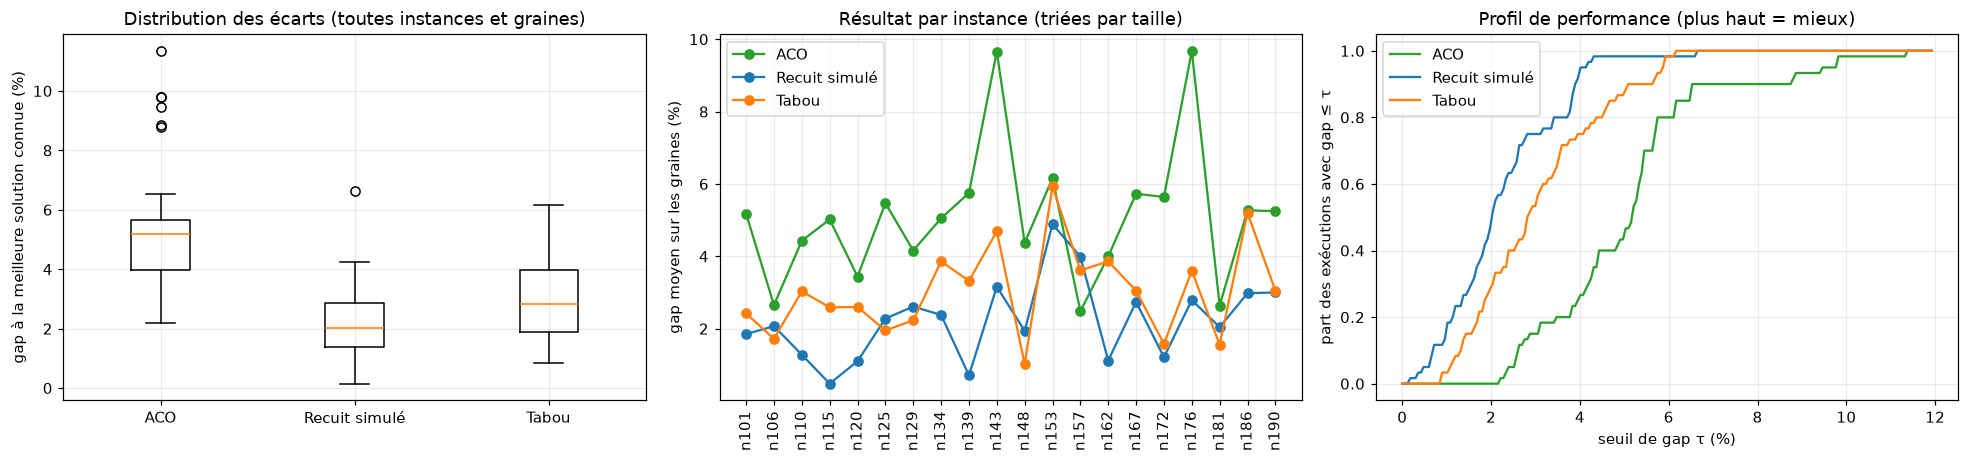

In [18]:
resume = df.groupby("algo").agg(gap_moyen=("gap", "mean"), gap_median=("gap", "median"), gap_ecart_type=("gap", "std"),
                                gap_min=("gap", "min"), gap_max=("gap", "max"),
                                taux_faisable=("faisable", "mean"), temps_moyen_s=("temps", "mean")).round(2)
resume["part_sous_5pct"] = df.assign(ok5=(df["gap"] < 5)).groupby("algo")["ok5"].mean().round(2)
display(resume)

par_instance = df.pivot_table(index=["instance", "n"], columns="algo", values="gap", aggfunc="mean").round(2).sort_index(level="n")
display(par_instance)

fig, ax = plt.subplots(1, 3, figsize=(18, 4.3))
algos_l = list(resume.index)
ax[0].boxplot([df[(df["algo"] == a) & df["faisable"]]["gap"] for a in algos_l])
ax[0].set_xticklabels(algos_l); ax[0].set_ylabel("gap à la meilleure solution connue (%)")
ax[0].set_title("Distribution des écarts (toutes instances et graines)")
for a in algos_l:
    d = par_instance[a].reset_index()
    ax[1].plot(range(len(d)), d[a], "o-", label=a, color=COULEURS.get(a))
ax[1].set_xticks(range(len(par_instance))); ax[1].set_xticklabels([i.split("-")[1] for i, _ in par_instance.index], rotation=90)
ax[1].set_ylabel("gap moyen sur les graines (%)"); ax[1].set_title("Résultat par instance (triées par taille)"); ax[1].legend()
taus = np.linspace(0, max(1.0, np.nanmax(df["gap"]) * 1.05), 200)
for a in algos_l:
    g = np.where(df[df["algo"] == a]["faisable"], df[df["algo"] == a]["gap"], np.inf)
    ax[2].plot(taus, [(g <= t).mean() for t in taus], label=a, color=COULEURS.get(a))
ax[2].set_xlabel("seuil de gap τ (%)"); ax[2].set_ylabel("part des exécutions avec gap ≤ τ")
ax[2].set_title("Profil de performance (plus haut = mieux)"); ax[2].legend()
plt.tight_layout(); plt.show()

#### 3.2. Exécution sur les grandes instances

In [41]:
df = executer_essais("principal", ALGOS, CONFIG["instances_grandes"], CONFIG["graines"], CONFIG["limite_grandes"])
print(f"{len(df)} exécutions ({df['algo'].nunique()} algorithmes x {df['instance'].nunique()} instances x {df['seed'].nunique()} graines)")
print("échecs (infaisable ou erreur) :", int((~df["faisable"]).sum()), "| dépassements de temps :", int(df["depassement"].sum()))

  [principal] instance 1/4 terminée : XL-n1048-k237
  [principal] instance 2/4 terminée : XL-n1561-k75
  [principal] instance 3/4 terminée : XL-n2028-k617
  [principal] instance 4/4 terminée : XL-n3007-k658
36 exécutions (3 algorithmes x 4 instances x 3 graines)
échecs (infaisable ou erreur) : 0 | dépassements de temps : 0


,gap_moyen,gap_median,gap_ecart_type,gap_min,gap_max,taux_faisable,temps_moyen_s,part_sous_5pct
algo,,,,,,,,
ACO,5.65,5.39,2.46,2.98,9.15,1.0,30.15,0.50
Recuit simulé,4.36,3.05,2.98,2.02,10.41,1.0,30.08,0.75
Tabou,5.00,4.56,2.00,3.01,8.28,1.0,30.00,0.50


,algo,ACO,Recuit simulé,Tabou
instance,n,,,
XL-n1048-k237,1047,8.70,8.92,7.92
XL-n1561-k75,1560,3.81,3.03,3.62
XL-n2028-k617,2027,7.12,2.56,5.44
XL-n3007-k658,3006,2.98,2.95,3.01


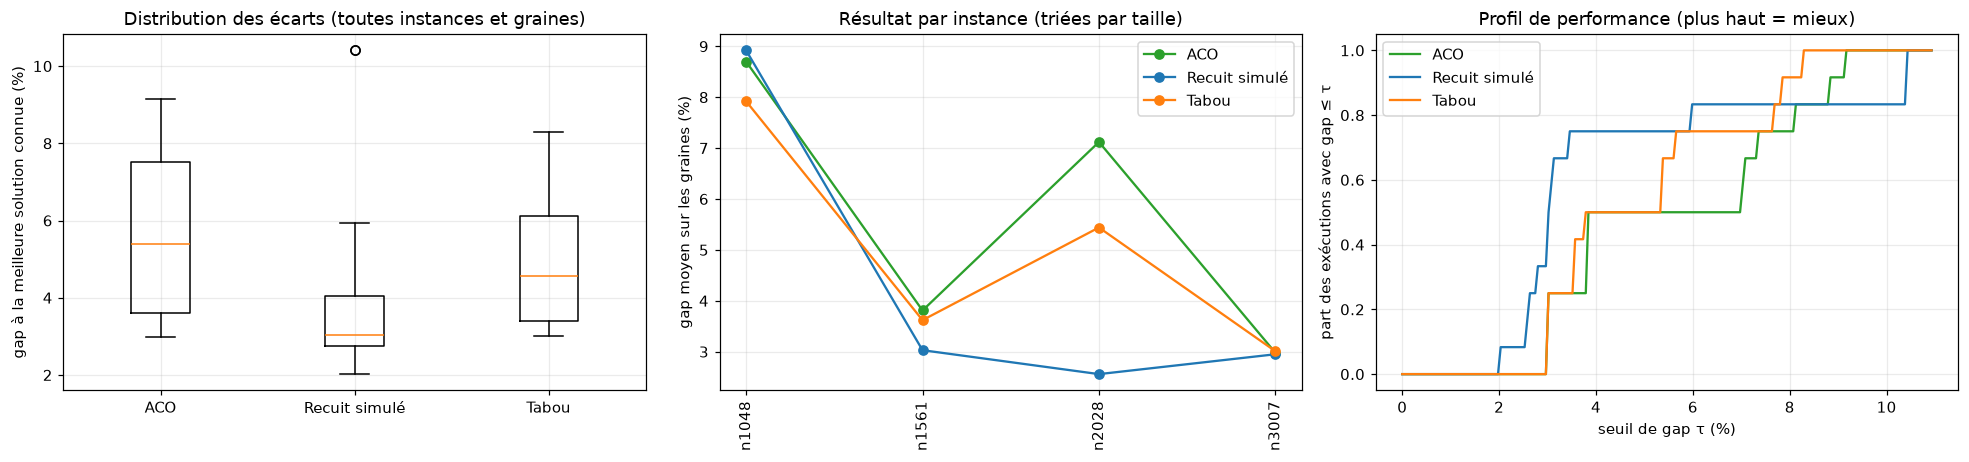

In [42]:
resume_grande = df.groupby("algo").agg(gap_moyen=("gap", "mean"), gap_median=("gap", "median"), gap_ecart_type=("gap", "std"),
                                gap_min=("gap", "min"), gap_max=("gap", "max"),
                                taux_faisable=("faisable", "mean"), temps_moyen_s=("temps", "mean")).round(2)
resume_grande["part_sous_5pct"] = df.assign(ok5=(df["gap"] < 5)).groupby("algo")["ok5"].mean().round(2)
display(resume_grande)

par_instance_grande = df.pivot_table(index=["instance", "n"], columns="algo", values="gap", aggfunc="mean").round(2).sort_index(level="n")
display(par_instance_grande)

fig, ax = plt.subplots(1, 3, figsize=(18, 4.3))
algos_l = list(resume_grande.index)
ax[0].boxplot([df[(df["algo"] == a) & df["faisable"]]["gap"] for a in algos_l])
ax[0].set_xticklabels(algos_l); ax[0].set_ylabel("gap à la meilleure solution connue (%)")
ax[0].set_title("Distribution des écarts (toutes instances et graines)")
for a in algos_l:
    d = par_instance_grande[a].reset_index()
    ax[1].plot(range(len(d)), d[a], "o-", label=a, color=COULEURS.get(a))
ax[1].set_xticks(range(len(par_instance_grande))); ax[1].set_xticklabels([i.split("-")[1] for i, _ in par_instance_grande.index], rotation=90)
ax[1].set_ylabel("gap moyen sur les graines (%)"); ax[1].set_title("Résultat par instance (triées par taille)"); ax[1].legend()
taus = np.linspace(0, max(1.0, np.nanmax(df["gap"]) * 1.05), 200)
for a in algos_l:
    g = np.where(df[df["algo"] == a]["faisable"], df[df["algo"] == a]["gap"], np.inf)
    ax[2].plot(taus, [(g <= t).mean() for t in taus], label=a, color=COULEURS.get(a))
ax[2].set_xlabel("seuil de gap τ (%)"); ax[2].set_ylabel("part des exécutions avec gap ≤ τ")
ax[2].set_title("Profil de performance (plus haut = mieux)"); ax[2].legend()
plt.tight_layout(); plt.show()

### Interprétation des résultats

**Qualité.** Le recuit simulé a le meilleur écart moyen à la meilleure solution connue : **2,23 %**, contre 3,04 % pour le tabou et 5,10 % pour l'ACO. La médiane donne le même classement (2,02 / 2,82 / 5,18). Le recuit simulé tient la barre des 5 % dans **98 %** des exécutions, le tabou dans 87 % et l'ACO dans 45 % seulement.

**Régularité.** Le recuit simulé a aussi la plus faible dispersion (écart-type 1,25, contre 1,45 pour le tabou et 1,95 pour l'ACO). Son pire cas (6,62 %) est un peu au-dessus de celui du tabou (6,15 %), mais bien en dessous de celui de l'ACO (11,35 %). Son meilleur cas est le plus proche de la meilleure solution connue (0,15 %).

**Lecture du rang.** Le recuit simulé est devant le tabou d'environ 0,8 point de gap, et l'ACO est environ 3 points derrière le recuit simulé. La différence recuit simulé / ACO est large, alors que la différence recuit simulé / tabou est plus modeste. Seuls les tests de Friedman et de Wilcoxon avec correction de Holm (§4) disent si ces écarts sont significatifs.

Le recuit simulé fait des millions de petits pas par seconde, tandis que le tabou évalue un échantillon de mouvements à chaque pas et en fait donc beaucoup moins. L'ACO consacre son temps à construire des solutions entières, que la descente locale doit ensuite réparer.

**Choix retenu : le recuit simulé**. Pour ce fait, représentons graphiquement la solution obtenue avec le récuit simulé testé sur une instance moyenne ( 'X-n101-k25' )

X-n200-k36 : n=199, Q=402, k minimal=36, meilleure solution connue=58578
Clarke & Wright : coût 62123  (écart 6.05 %)
recuit graine 0 : coût 59497  écart 1.57 %  faisable=True  36 tournées  14.9 s  (134 k it/s)
recuit graine 1 : coût 59534  écart 1.63 %  faisable=True  36 tournées  11.7 s  (171 k it/s)
recuit graine 2 : coût 60200  écart 2.77 %  faisable=True  37 tournées  14.0 s  (143 k it/s)


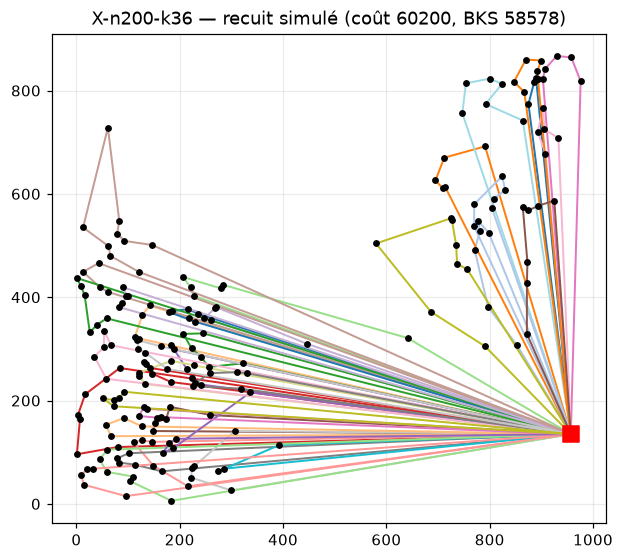

In [45]:
def tracer_solution(inst, routes, titre=""):
    # Dessine les tournées d'une solution (une couleur par tournée)
    fig, ax = plt.subplots(figsize=(6.5, 6.5))
    cmap = plt.get_cmap("tab20")
    for i, r in enumerate(routes):
        chemin = [0] + r + [0]
        ax.plot([inst["x"][c] for c in chemin], [inst["y"][c] for c in chemin], "-", lw=1.3, color=cmap(i % 20))
    ax.scatter(inst["x"][1:], inst["y"][1:], s=12, c="k", zorder=3)
    ax.scatter(inst["x"][0], inst["y"][0], marker="s", s=110, c="red", zorder=4)
    ax.set_aspect("equal"); ax.set_title(titre); plt.show()

nom = "X-n200-k36"
inst = lire_vrplib(f"{DOSSIER_X}/{nom}.vrp")
sv = savings(inst)
cout_sv, _, _ = verifier(inst, sv)
print(f"{nom} : n={inst['n']}, Q={inst['Q']}, k minimal={inst['kmin']}, meilleure solution connue={BKS[nom]}")
print(f"Clarke & Wright : coût {cout_sv:.0f}  (écart {100*(cout_sv/BKS[nom]-1):.2f} %)")
for seed in range(3):
    r = recuit_simule(inst, iters=2_000_000, seed=seed)
    c, ok, msg = verifier(inst, r["routes"])
    print(f"recuit graine {seed} : coût {c:.0f}  écart {100*(c/BKS[nom]-1):.2f} %  faisable={ok}  "
          f"{len(r['routes'])} tournées  {r['temps']:.1f} s  ({r['iters']/r['temps']/1000:.0f} k it/s)")
tracer_solution(inst, r["routes"], f"{nom} — recuit simulé (coût {c:.0f}, BKS {BKS[nom]})")

**Interprétation.** Clarke & Wright laisse 5,51 % d'écart ; le recuit descend à 0,28-1,64 % selon la graine, en moins de 2 s (≈ 1 M d'itérations par seconde). Les trois graines donnent trois solutions différentes (28044, 27988, 27669) : l'algorithme est **stochastique**, un seul essai ne permet pas de conclure, d'où l'étude statistique du §9. Le tracé montre 26 petites tournées (≈ 4 clients chacune) en « pétales » autour du dépôt, profil attendu pour X-n101-k25.

## 7. Comportement de l'algorithme : la trajectoire

Avant de généraliser, on regarde **comment** l'algorithme arrive à son résultat : on enregistre, tous les 30 000 itérations, le coût de la solution courante, la meilleure solution faisable et la température.

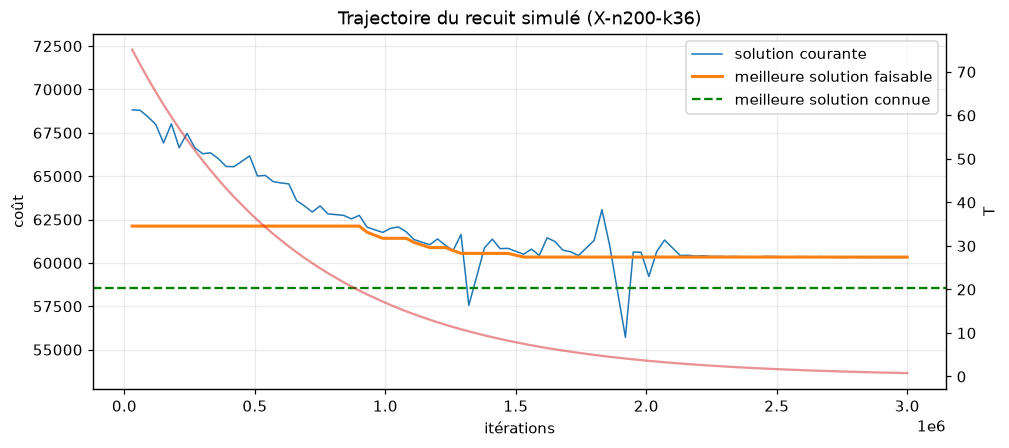

coût final 60338  (écart 3.00 %), faisable=True


In [47]:
inst = lire_vrplib(f"{DOSSIER_X}/X-n200-k36.vrp")
r = recuit_simule(inst, iters=3_000_000, seed=0, trace_every=30_000)
tr = np.array([(t[0], t[1], t[2], t[3]) for t in r["trace"]])
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(tr[:, 0], tr[:, 1], label="solution courante", lw=1)
ax.plot(tr[:, 0], tr[:, 2], label="meilleure solution faisable", lw=2)
ax.axhline(BKS["X-n200-k36"], color="green", ls="--", label="meilleure solution connue")
ax.set_xlabel("itérations"); ax.set_ylabel("coût"); ax.set_ylim(BKS["X-n200-k36"] * 0.90, BKS["X-n200-k36"] * 1.25)
ax2 = ax.twinx(); ax2.plot(tr[:, 0], tr[:, 3], color="tab:red", alpha=.5, label="température"); ax2.set_ylabel("T"); ax2.grid(False)
ax.legend(loc="upper right"); plt.title("Trajectoire du recuit simulé (X-n200-k36)"); plt.show()
c, ok, _ = verifier(inst, r["routes"])
print(f"coût final {c:.0f}  (écart {100*(c/BKS['X-n200-k36']-1):.2f} %), faisable={ok}")

**Comment lire la courbe ?**
- **Phase chaude** (début) : la solution courante (bleu) est bien *plus mauvaise* que la solution initiale de Clarke & Wright (≈ 62 100) : l'algorithme accepte beaucoup de mouvements dégradants pour explorer. La meilleure solution faisable (orange) reste celle de départ pendant les premières ≈ 0,9 M d'itérations : tant que $T$ est élevée, aucun état faisable ne la dépasse.
- **Refroidissement** : quand $T$ baisse, la courbe courante descend et la meilleure solution s'améliore par paliers (de 62 100 à ≈ 60 300 entre 0,9 M et 1,6 M d'itérations).
- **Pics vers le bas de la courbe bleue** : ce sont des états **infaisables** (un camion surchargé) : leur coût en distance peut passer *sous* la meilleure solution connue.
- **Phase froide** (dernière moitié) : la solution courante se rapproche de la meilleure (quelques pics d'états infaisables subsistent jusqu'à ≈ 2 M d'itérations) et la meilleure solution ne bouge plus. Les 1,5 million d'itérations finales n'ont rien apporté pour cette exécution : un budget plus court, ou un **réchauffage**, serait plus rentable.
- Résultat final : 60338, soit 3,00 % de la meilleure solution connue, contre 6,05 % pour la solution initiale.

## 8. Plan d'expérience et étude statistique

### 8.1 Qualité statistique

,n,gap_moy,gap_min,gap_max,gap_savings,temps
instance,,,,,,
X-n101-k25,100,1.12,0.28,1.64,5.51,1.76
X-n106-k14,105,1.67,1.42,1.88,3.84,1.98
X-n110-k13,109,0.73,0.29,1.00,5.93,1.57
X-n115-k10,114,0.53,0.24,0.69,5.81,1.54
X-n120-k6,119,0.95,0.34,1.66,9.07,1.55
X-n125-k30,124,2.09,1.53,2.55,6.63,1.82
X-n129-k18,128,2.35,1.83,2.83,4.69,1.73
X-n134-k13,133,2.26,1.47,2.96,5.51,1.76
X-n139-k10,138,0.47,0.43,0.52,6.72,1.53


Toutes les solutions faisables : True  (60 exécutions)
gap (%) — moyenne 1.93 | médiane 1.71 | écart-type 1.17 | min 0.24 | Q1 0.99 | Q3 2.44 | max 5.03
gap de Clarke & Wright seul : moyenne 6.94 %  → le recuit réduit l'écart de 5.01 points en 1.7 s en moyenne


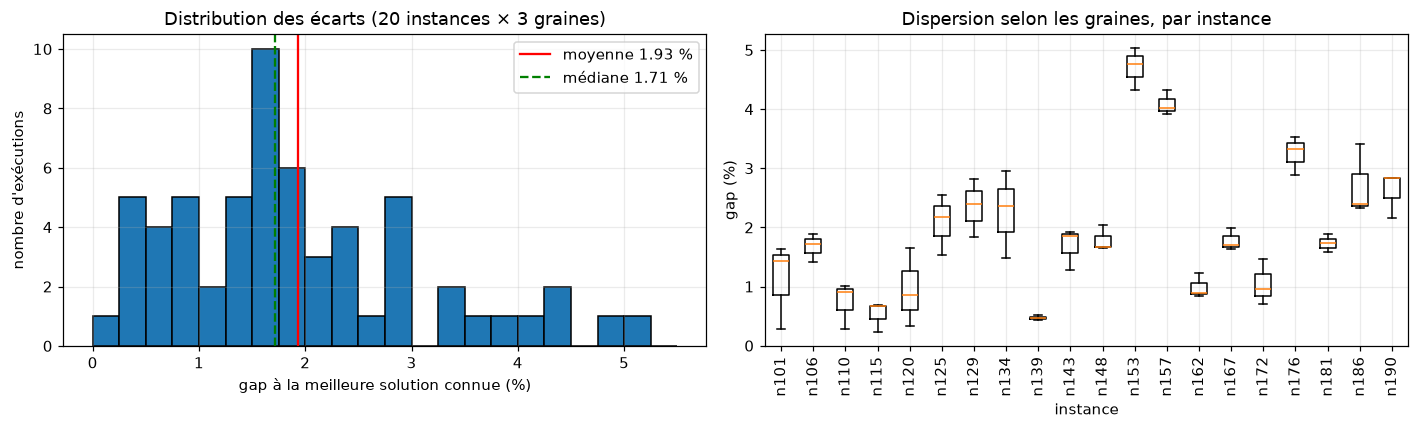

In [49]:
INSTANCES_20 = ["X-n101-k25", "X-n106-k14", "X-n110-k13", "X-n115-k10", "X-n120-k6", "X-n125-k30", "X-n129-k18",
                "X-n134-k13", "X-n139-k10", "X-n143-k7", "X-n148-k46", "X-n153-k22", "X-n157-k13", "X-n162-k11",
                "X-n167-k10", "X-n172-k51", "X-n176-k26", "X-n181-k23", "X-n186-k15", "X-n190-k8"]

def exp_qualite():
    res = []
    for nom in INSTANCES_20:
        inst = lire_vrplib(f"{DOSSIER_X}/{nom}.vrp")
        cout_sv = verifier(inst, savings(inst))[0]
        for s in range(3):
            r = recuit_simule(inst, iters=2_000_000, seed=s)
            c, ok, _ = verifier(inst, r["routes"])
            res.append(dict(instance=nom, n=inst["n"], seed=s, cout=c, faisable=ok, temps=r["temps"], savings=cout_sv))
    return res

df_q = pd.DataFrame(avec_cache("qualite", exp_qualite))
df_q["bks"] = df_q["instance"].map(BKS)
df_q["gap"] = 100 * (df_q["cout"] / df_q["bks"] - 1)
df_q["gap_savings"] = 100 * (df_q["savings"] / df_q["bks"] - 1)
par_inst = df_q.groupby("instance").agg(n=("n", "first"), gap_moy=("gap", "mean"), gap_min=("gap", "min"),
                                         gap_max=("gap", "max"), gap_savings=("gap_savings", "first"),
                                         temps=("temps", "mean")).round(2).sort_values("n")
display(par_inst)
print(f"Toutes les solutions faisables : {df_q['faisable'].all()}  ({len(df_q)} exécutions)")
g = df_q["gap"]
print(f"gap (%) — moyenne {g.mean():.2f} | médiane {g.median():.2f} | écart-type {g.std():.2f} | min {g.min():.2f} | "
      f"Q1 {g.quantile(.25):.2f} | Q3 {g.quantile(.75):.2f} | max {g.max():.2f}")
print(f"gap de Clarke & Wright seul : moyenne {par_inst['gap_savings'].mean():.2f} %  → le recuit réduit l'écart de "
      f"{par_inst['gap_savings'].mean() - par_inst['gap_moy'].mean():.2f} points en {df_q['temps'].mean():.1f} s en moyenne")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(g, bins=np.arange(0, g.max() + 0.5, 0.25), edgecolor="k")
ax[0].axvline(g.mean(), color="r", label=f"moyenne {g.mean():.2f} %"); ax[0].axvline(g.median(), color="g", ls="--", label=f"médiane {g.median():.2f} %")
ax[0].set_xlabel("gap à la meilleure solution connue (%)"); ax[0].set_ylabel("nombre d'exécutions"); ax[0].legend()
ax[0].set_title("Distribution des écarts (20 instances × 3 graines)")
ordre = par_inst.index
ax[1].boxplot([df_q[df_q["instance"] == i]["gap"] for i in ordre])
ax[1].set_xticklabels([i.split("-")[1] for i in ordre])
ax[1].set_xlabel("instance"); ax[1].set_ylabel("gap (%)"); ax[1].tick_params(axis="x", rotation=90)
ax[1].set_title("Dispersion selon les graines, par instance")
plt.tight_layout(); plt.show()

**Interprétation.**
- **Faisabilité** : les 60 exécutions fournissent une solution faisable (vérifiée de façon indépendante).
- **Niveau de qualité** : gap moyen **1,93 %**, médiane 1,71 %, écart-type 1,17 ; 85 % des exécutions sont sous 3 % et 98 % sous 5 %. La solution de départ (Clarke & Wright) était à 6,94 % en moyenne : le recuit supprime ≈ 5 points d'écart en 1,7 s par exécution. Le critère d'évaluation du projet (gap < 7-10 %) est largement tenu.
- **Asymétrie** : la médiane est inférieure à la moyenne et l'histogramme a une queue à droite : quelques instances difficiles tirent la moyenne vers le haut. Prendre la meilleure des 3 graines ramène le gap moyen à 1,56 %.
- **Variabilité** : l'étendue entre graines est faible (0,7 point en moyenne, 1,5 au maximum), alors que l'écart **entre instances** est grand (de 0,47 % pour X-n139 à 4,70 % pour X-n153). La difficulté dépend donc surtout de l'instance et non du hasard ; X-n153 et X-n157 sont difficiles pour *toutes* les graines (biais plutôt que variance). Nous n'avons pas identifié la cause : c'est une piste du §11.
- **Taille** : la corrélation entre $n$ et le gap est modérée (0,40) sur cet intervalle étroit de tailles (100-190 clients).

### 9.2 Influence des paramètres
Pour chaque valeur d'un paramètre, on lance 6 instances × 2 graines et on trace la **moyenne du gap** avec une **bande d'un écart-type**, comme dans le workshop.

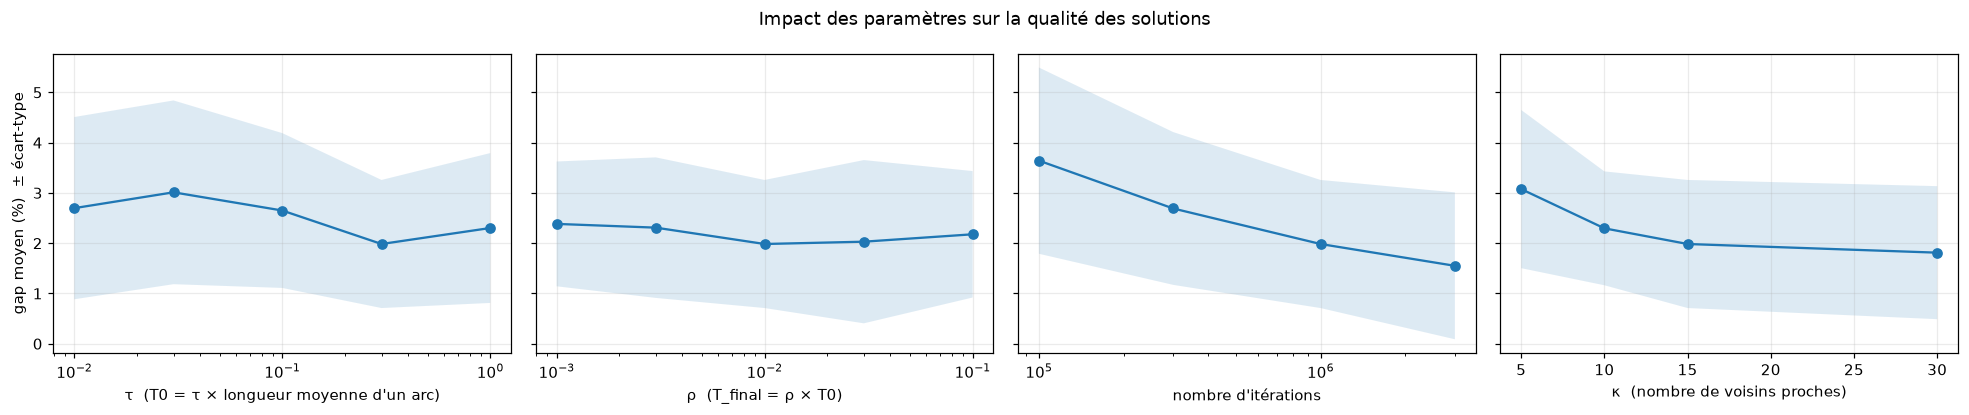

gap_moyen  ecart_type  temps_moyen_s
etude valeur                                           
iters 100000.000        3.64        1.85           0.08
      300000.000        2.69        1.52           0.25
      1000000.000       1.98        1.27           0.83
      3000000.000       1.55        1.46           2.54
kappa 5.000             3.08        1.57           0.82
      10.000            2.30        1.13           0.87
      15.000            1.98        1.27           0.87
      30.000            1.81        1.32           0.85
rho   0.001             2.38        1.24           0.85
      0.003             2.31        1.40           0.85
      0.010             1.98        1.27           0.85
      0.030             2.03        1.62           0.86
      0.100             2.18        1.26           0.87
tau   0.010             2.70        1.81           0.82
      0.030             3.01        1.83           0.82
      0.100             2.65        1.54           0.85
      0.300             1.98        1.27           0.86
      1.000             2.30        1.49           0.91

In [50]:
INST_PARAM = ["X-n101-k25", "X-n115-k10", "X-n129-k18", "X-n143-k7", "X-n157-k13", "X-n172-k51"]
cache_inst = {nom: lire_vrplib(f"{DOSSIER_X}/{nom}.vrp") for nom in INST_PARAM}

def exp_param():
    res = []
    plans = {"tau": [("t0_rel", v, 1_000_000) for v in (0.01, 0.03, 0.1, 0.3, 1.0)],
             "rho": [("tf_ratio", v, 1_000_000) for v in (0.1, 0.03, 0.01, 0.003, 0.001)],
             "iters": [("iters", v, v) for v in (100_000, 300_000, 1_000_000, 3_000_000)],
             "kappa": [("nb_voisins", v, 1_000_000) for v in (5, 10, 15, 30)]}
    for etude, liste in plans.items():
        for param, valeur, iters in liste:
            for nom in INST_PARAM:
                for s in range(2):
                    args = dict(iters=iters, seed=s)
                    if param != "iters":
                        args[param] = valeur
                    r = recuit_simule(cache_inst[nom], **args)
                    c, ok, _ = verifier(cache_inst[nom], r["routes"])
                    res.append(dict(etude=etude, valeur=valeur, instance=nom, seed=s, gap=100 * (c / BKS[nom] - 1) if ok else None,
                                    temps=r["temps"]))
    return res

df_p = pd.DataFrame(avec_cache("parametres", exp_param))
titres = {"tau": ("τ  (T0 = τ × longueur moyenne d'un arc)", True), "rho": ("ρ  (T_final = ρ × T0)", True),
          "iters": ("nombre d'itérations", True), "kappa": ("κ  (nombre de voisins proches)", False)}
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8), sharey=True)
for ax, (etude, (lab, logx)) in zip(axes, titres.items()):
    d = df_p[df_p["etude"] == etude].groupby("valeur")["gap"].agg(["mean", "std"]).reset_index()
    ax.plot(d["valeur"], d["mean"], "o-")
    ax.fill_between(d["valeur"], d["mean"] - d["std"], d["mean"] + d["std"], alpha=.15)
    if logx:
        ax.set_xscale("log")
    ax.set_xlabel(lab)
axes[0].set_ylabel("gap moyen (%)  ± écart-type")
plt.suptitle("Impact des paramètres sur la qualité des solutions"); plt.tight_layout(); plt.show()
display(df_p.groupby(["etude", "valeur"]).agg(gap_moyen=("gap", "mean"), ecart_type=("gap", "std"), temps_moyen_s=("temps", "mean")).round(2))

**Interprétation** (différences *appariées* par rapport à la valeur par défaut, sur les mêmes 12 couples instance-graine ; les bandes du graphique sont larges car l'écart-type mêle la variabilité entre instances).
- **Nombre d'itérations** : effet le plus net. Le gap moyen passe de 3,64 % (100 000 it.) à 2,69 %, 1,98 % et 1,55 % (3 M) : environ −0,4 à −1,0 point chaque fois qu'on triple le budget, avec des rendements décroissants. Le temps croît linéairement (0,08 s → 2,5 s).
- **Voisinage $\kappa$** : passer de 5 à 15 voisins gagne ≈ 1,1 point ; au-delà le gain est faible (−0,17 point à 30) et le temps n'augmente pas (le coût par itération ne dépend pas de $\kappa$). Un voisinage trop étroit (5) coupe des mouvements utiles.
- **Température initiale $\tau$** : $\tau=0{,}3$ est la meilleure valeur testée, mais l'effet est modeste et bruité (écart apparié de 0,3 à 1,0 point, avec un écart-type de 0,8 à 1,8) ; seules les valeurs 0,03 et 0,1 sont nettement moins bonnes (≈ 2 erreurs-types). Trop froid : on reste près de la solution de départ ; trop chaud : on gâche du budget.
- **Température finale $\rho$** : courbe quasi plate (de 1,98 % à 2,38 %) : l'algorithme est **peu sensible** à ce paramètre, avec un léger avantage pour $\rho=0{,}01$.
- **Réserve** : les valeurs par défaut ($\tau=0{,}3$, $\rho=0{,}01$, $\kappa=15$) ont été choisies lors d'essais préliminaires sur X-n101, X-n200 et X-n303 ; X-n101 est aussi dans cette étude, qui n'est donc pas totalement indépendante du réglage.
- **Conclusion pratique** : le levier principal est le **budget d'itérations** ; les autres paramètres demandent seulement de rester dans une zone raisonnable.

### 9.3 Impact du nombre de clients
Budget proportionnel à la taille : 10 000 itérations par client, 2 graines, paramètres par défaut. On y ajoute les 20 instances de 9.1 pour tracer l'écart en fonction de $n$.

,n,gap_recuit,gap_savings,temps_s,faisable
instance,,,,,
X-n200-k36,199,1.35,6.05,1.80,True
X-n303-k21,302,2.79,9.21,3.03,True
X-n401-k29,400,2.01,5.81,5.08,True
X-n502-k39,501,1.39,4.01,6.04,True
X-n1001-k43,1000,4.57,7.04,11.13,True


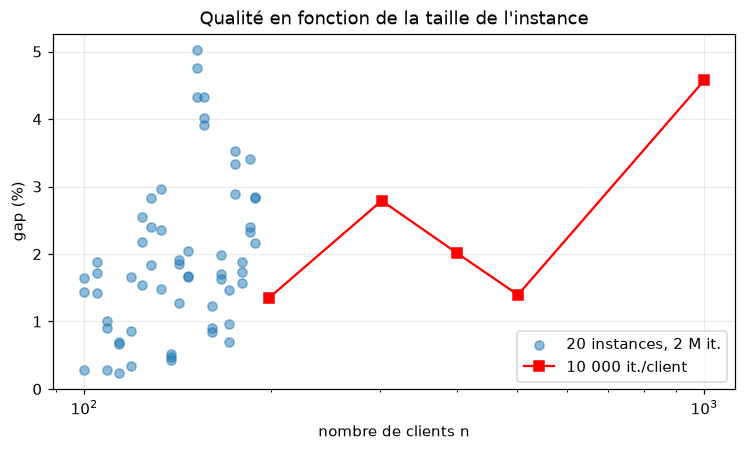

In [64]:
INST_TAILLE = ["X-n200-k36", "X-n303-k21", "X-n401-k29", "X-n502-k39", "X-n1001-k43"]

def exp_taille():
    res = []
    for nom in INST_TAILLE:
        inst = lire_vrplib(f"{DOSSIER_X}/{nom}.vrp")
        cout_sv = verifier(inst, savings(inst))[0]
        for s in range(2):
            r = recuit_simule(inst, iters=10_000 * inst["n"], seed=s)
            c, ok, _ = verifier(inst, r["routes"])
            res.append(dict(instance=nom, n=inst["n"], seed=s, cout=c, faisable=ok, temps=r["temps"], savings=cout_sv))
    return res

df_t = pd.DataFrame(avec_cache("taille", exp_taille))
df_t["bks"] = df_t["instance"].map(BKS)
df_t["gap"] = 100 * (df_t["cout"] / df_t["bks"] - 1)
df_t["gap_savings"] = 100 * (df_t["savings"] / df_t["bks"] - 1)
display(df_t.groupby("instance").agg(n=("n", "first"), gap_recuit=("gap", "mean"), gap_savings=("gap_savings", "first"),
                                      temps_s=("temps", "mean"), faisable=("faisable", "all")).round(2).sort_values("n"))

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.scatter(df_q["n"], df_q["gap"], alpha=.5, label="20 instances, 2 M it.")
moy = df_t.groupby("n")["gap"].mean()
ax.plot(moy.index, moy.values, "rs-", label="10 000 it./client")
ax.set_xscale("log"); ax.set_xlabel("nombre de clients n"); ax.set_ylabel("gap (%)"); ax.legend()
ax.set_title("Qualité en fonction de la taille de l'instance"); plt.show()

**Interprétation.**
- **Gap** : de 1,35 % (200 clients) à 4,57 % (1000 clients), avec 10 000 itérations par client. Tous les résultats sont faisables et sous 7 %, y compris sur X-n1001-k43 (4,57 % en 11 s).
- **Pas de tendance monotone** : 1,35 % → 2,79 % → 2,01 % → 1,39 % → 4,57 %. À budget par client constant, la difficulté dépend autant de la structure de l'instance (capacité, répartition) que de la taille ; seule la plus grande instance se détache nettement.
- **Gain sur Clarke & Wright** : de 2,5 à 6,4 points ; il diminue pour les grandes instances (2,5 points à 1000 clients) : avec le même nombre d'itérations *par client*, il y a plus de structure à améliorer et le budget est vite saturé.
- **Temps** : de 1,8 s à 11 s, proportionnel au budget (≈ 0,9 à 1,1 M it./s) : le coût par itération ne dépend pas de $n$, conformément à l'analyse du §5.
- Seulement 2 graines par instance : ces valeurs sont indicatives.

## 11. Limites, améliorations, conclusion

**Limites constatées.**

1. **Réglage et référence.** Les paramètres par défaut ont été choisis sur quelques instances (X-n101, X-n200, X-n303) ; les gaps sont mesurés par rapport aux meilleures solutions connues de la littérature (Vidal, 2022), qui ont pu être légèrement améliorées depuis.
2. **Un défaut corrigé en cours de route.** Dans une première version, 3 exécutions sur 60 ne dépassaient pas la solution initiale (gap jusqu'à 10 %) : la pénalité $\lambda$ était plafonnée trop bas, et l'algorithme préférait rester infaisable. La borne vaut maintenant « le coût moyen d'une tournée par unité de surcharge » (§5). Les résultats de ce notebook sont ceux de la version corrigée.
3. **Passage à l'échelle.** À 2000-5000 clients le gain sur Clarke & Wright est inférieur à 1,4 % au budget testé (§9.4), et Python pur plafonne à ≈ 0,4-1,2 M it./s. Pistes : code compilé (Numba, C++), décomposition de l'instance en sous-problèmes par secteurs, voisinage plus riche (échanges de segments, *SWAP\**).
4. **Instances difficiles.** X-n153 et X-n157 restent à 4-5 % pour toutes les graines : cause non identifiée. Pistes : analyse de la structure (rapport capacité/demandes), **réchauffages** successifs au lieu d'un seul refroidissement (la phase froide de la trajectoire est gaspillée, §7).
5. **Statistiques.** 3 graines (2 pour les études de taille et de paramètres) et aucune comparaison inférentielle entre algorithmes : un test apparié (Wilcoxon) sur davantage de graines serait plus rigoureux. Les autres métaheuristiques (tabou, génétique, fourmis) n'ont été comparées qu'à petite échelle (annexe), avec des budgets non équivalents.
6. **Modèle.** Distances symétriques et constantes (H5) : le **trafic variable par tranche horaire** de l'énoncé ($t_{ij}(\tau)$) n'est pas traité. Les bornes de l'exact (relaxation MTZ ≈ 70 % de l'optimum) pourraient être resserrées par des coupes de capacité (branch-and-cut).

**Conclusion.** On a (i) corrigé et implémenté le modèle PLNE du établi au livrable 1 et mesuré ses limites, (ii) implémenté trois métaheuristiques puis, fait le choix du recuit simulé sur l'analyse de qualités des résultats obtenus, (iii) formalisé et implémenté un recuit simulé renforcé, (iv) étudié son comportement sur 20 instances du benchmark VRPLIB, ses paramètres, sa taille limite et (v) montré qu'il s'étend aux fenêtres de temps. Les chiffres de synthèse sont dans les interprétations ci-dessus.

## 12. Références
- Clarke, G., Wright, J. W. (1964). Scheduling of vehicles from a central depot to a number of delivery points. *Operations Research*, 12(4), 568–581.
- Dantzig, G. B., Ramser, J. H. (1959). The truck dispatching problem. *Management Science*, 6(1), 80–91.
- Kirkpatrick, S., Gelatt, C. D., Vecchi, M. P. (1983). Optimization by simulated annealing. *Science*, 220(4598), 671–680.
- Metropolis, N. et al. (1953). Equation of state calculations by fast computing machines. *Journal of Chemical Physics*, 21(6), 1087–1092.
- Miller, C. E., Tucker, A. W., Zemlin, R. A. (1960). Integer programming formulations and traveling salesman problems. *Journal of the ACM*, 7(4), 326–329.
- Papadimitriou, C. H. (1977). The Euclidean travelling salesman problem is NP-complete. *Theoretical Computer Science*, 4(3), 237–244.
- Papadimitriou, C. H., Steiglitz, K. (1982). *Combinatorial Optimization: Algorithms and Complexity*. Prentice-Hall.
- Potvin, J.-Y., Rousseau, J.-M. (1995). An exchange heuristic for routeing problems with time windows. *Journal of the Operational Research Society*, 46(12), 1433–1446.
- Solomon, M. M. (1987). Algorithms for the vehicle routing and scheduling problems with time window constraints. *Operations Research*, 35(2), 254–265.
- Toth, P., Vigo, D. (2003). The granular tabu search and its application to the vehicle-routing problem. *INFORMS Journal on Computing*, 15(4), 333–346.
- Toth, P., Vigo, D. (2014). *Vehicle Routing: Problems, Methods, and Applications* (2nd ed.). SIAM.
- Uchoa, E., Pecin, D., Pessoa, A., Poggi, M., Vidal, T., Subramanian, A. (2017). New benchmark instances for the capacitated vehicle routing problem. *European Journal of Operational Research*, 257(3), 845–858.
- Vidal, T. (2022). Hybrid genetic search for the CVRP: open-source implementation and SWAP* neighborhood. *Computers & Operations Research*, 140, 105643 (valeurs de référence des instances X).